# Tumor stress vs target-gene substates

Design and results: `plans/stress_substate_exploration.md`. Five samples, the 623,838 pooled tumor cells of the
sample-corrected pooled subtyping, both labellings (cytoplasmic and nuclear expression of the 634 target genes).

Two questions: **(a)** are the cytoplasmic target-gene substates connected to tumor stress? **(b)** is the
cytoplasmic expression of the target genes more closely related to stress than the nuclear expression?

Two correspondence approaches, both saved as peers: **approach 1** stress scores / groups across the substates
(profiles, odds ratios); **approach 2** two explicit stress labellings of every cell (environmental archetype from
the expression-free axes, expression archetype from the four signature scores) compared label against label. The
summaries name the approach with the strongest signal. Expression signatures use their canonical gene lists; the
minus-634 arm of the review run was retired on 2026-11-08 (weaker on every metric, same associations; rationale
in the plan document). The SG-marker score and the granule-burden axes are stress axes but not subtyping features.

Outputs (`output/1_exploration/stress/`, emptied at the start of the run):

- `stress_axes/`: the per-cell stress table (cached; `REBUILD = True` recomputes it), composites, the stress
  subtypes and their maps;
- `cytoplasmic/`, `nuclear/`: the same self-contained analysis for each substate labelling (question a), incl.
  a Sankey-style flow figure between the environmental archetypes, the substates and the expression archetypes;
- `comparison/`: cytoplasmic vs nuclear (question b);
- `summary.txt`: overall answers.

In [1]:
import os, shutil, time, warnings
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from anndata.io import read_elem
from scipy.stats import spearmanr

import stress_utils as su
import stress_figures as sf
from stress_utils import AXES, SAMPLES, SHORT

warnings.filterwarnings("ignore")
sc.settings.verbosity = 0
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200)

REBUILD = False
OUT = "../../output/1_exploration/stress/"
SMOKE = os.environ.get("STRESS_SMOKE", "")          # development only: path of a scratch output folder -> 40k-cell subsample, 10 bootstraps
if SMOKE:
    OUT = SMOKE.rstrip("/") + "/"
D = {"axes": OUT + "stress_axes/", "cyto": OUT + "cytoplasmic/", "nuc": OUT + "nuclear/", "cmp": OUT + "comparison/"}
POOLED = {"cyto": "../../output/1_exploration/pooled_sample_corrected/",
          "nuc": "../../output/1_exploration/pooled_sample_corrected_nuclear/"}
OBJ = {"cyto": POOLED["cyto"] + "adata_pooled_cytoplasmic_embedded.h5ad",
       "nuc": POOLED["nuc"] + "adata_pooled_nuclear_embedded.h5ad"}
CHAR = {"cyto": POOLED["cyto"] + "characteristics/cell_annotations_cytoplasmic.csv",
        "nuc": POOLED["nuc"] + "characteristics/cell_annotations_nuclear.csv"}
COMP_NAME = {"cyto": "cytoplasmic", "nuc": "nuclear"}
B_BOOT = 10 if SMOKE else 100
N_FOLDS = 5
SEED = 0
rng = np.random.default_rng(SEED)

# Empty the output folder; the per-cell stress table (part 1, unchanged definition) is the only file carried over
CACHE = D["axes"] + "stress_scores.csv"
if SMOKE:
    CACHE = next(p for p in ["../../output/1_exploration/stress/stress_axes/stress_scores.csv", "../../output/1_exploration/stress/stress_scores.csv"] if os.path.exists(p))
    if os.path.exists(OUT):
        shutil.rmtree(OUT)
    for d in D.values():
        os.makedirs(d)
else:
    cache = next((p for p in [D["axes"] + "stress_scores.csv", OUT + "stress_scores.csv"] if os.path.exists(p) and not REBUILD), None)
    tmp = None
    if cache is not None:
        tmp = OUT.rstrip("/") + "_stress_scores_tmp.csv"
        shutil.move(cache, tmp)
    if os.path.exists(OUT):
        shutil.rmtree(OUT)
    for d in D.values():
        os.makedirs(d)
    if tmp is not None:
        shutil.move(tmp, CACHE)
    print("output folders:", list(D.values()), "| cached stress table:", cache is not None)

g634 = set(np.load("../../output/1_exploration/enrichment/overlap_genes_3plus_samples.npy", allow_pickle=True).tolist())
gmt = su.read_gmt("../../data/_utils/hallmark_pathways_filtered.gmt")
sg_df = pd.read_excel("../../data/_utils/SG_markers.xlsx")
sg_genes = sg_df[sg_df["Fraction of RNA molecules in SGs"] > 0.4]["gene"].tolist()
panel = np.load("../../data/Xenium_5K_BC/processed_data/gene_ids.npy", allow_pickle=True).astype(str).tolist()
sg_genes = [g for g in sg_genes if g in panel]
GENE_SETS = {"hypoxia": gmt["HALLMARK_HYPOXIA"], "heat_shock": su.HSP11,
             "tnfa_nfkb": gmt["HALLMARK_TNFA_SIGNALING_VIA_NFKB"], "ifng": gmt["HALLMARK_INTERFERON_GAMMA_RESPONSE"],
             "sg_markers": sg_genes}
for k, v in GENE_SETS.items():
    print(f"{k}: {len(v)} panel genes, {len(set(v) & g634)} in the 634 set")

AX = list(AXES)
AXIS_SET = {a: su.axis_set(a) for a in AX}                   # env | signature | other
AX_ENV = [a for a in AX if AXIS_SET[a] == "env"]
AX_SIG = list(su.EXPR_SIG)
AX_OTHER = [a for a in AX if AXIS_SET[a] == "other"]
AX_ORDER = AX_ENV + AX_SIG + AX_OTHER                        # row order of every axis table / heatmap
ROW_BREAKS = [len(AX_ENV), len(AX_ENV) + len(AX_SIG)]
AXSETS = [("env", AX_ENV), ("signature", AX_SIG)]            # the two axis sets scored in the signal-strength tables
def grp_names(ax):
    return ("Away", "Close") if AXES[ax][1] == "count" else su.GROUP_NAMES.get(ax, ("Low", "Mid", "High"))
def top_low(ax):
    g = grp_names(ax); return g[-1], g[0]
AXIS_TITLES = {"vascular_dist": "distance to nearest endothelial cell (um)", "vascular_n100": "endothelial cells within 100 um",
               "crowding": "crowding (1 / mean distance to 10 nearest cells)", "n_cells_30um": "cells within 30 um", "tumor_frac": "tumor fraction within 50 um",
               "nontumor_dist": "distance to nearest non-tumor cell (um)", "tcell_n50": "T cells within 50 um", "tcell_dist": "distance to nearest T cell (um)",
               "tcell_gzm_kernel": "GZM-weighted T-cell kernel", "immune_n50": "immune cells within 50 um", "myeloid_n50": "myeloid cells within 50 um",
               "myeloid_dist": "distance to nearest myeloid cell (um)", "fibroblast_n50": "fibroblasts within 50 um", "fibroblast_dist": "distance to nearest fibroblast (um)",
               "cell_area": "cell area (um2)", "nucleus_ratio": "nucleus / cell area", "k_vascular": "vascular marker kernel (label-free)",
               "k_cytotoxic": "cytotoxic marker kernel (label-free)", "k_myeloid": "myeloid marker kernel (label-free)", "k_stromal": "stromal marker kernel (label-free)",
               "hypoxia": "HALLMARK_HYPOXIA score", "heat_shock": "heat-shock (11 HSP) score", "tnfa_nfkb": "TNFA/NFKB score", "ifng": "IFNG response score",
               "sg_markers": "SG-marker score", "hypoxia_tf": "8-TF hypoxia rule", "granule_count": "granules per cell (log1p)", "granule_sg_transcripts": "SG transcripts in granules (log1p)"}

/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/Users/chenyang/miniconda3/envs/AIVC-env/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `annda

output folders: ['../../output/1_exploration/stress/stress_axes/', '../../output/1_exploration/stress/cytoplasmic/', '../../output/1_exploration/stress/nuclear/', '../../output/1_exploration/stress/comparison/'] | cached stress table: True


hypoxia: 96 panel genes, 26 in the 634 set
heat_shock: 11 panel genes, 1 in the 634 set
tnfa_nfkb: 110 panel genes, 17 in the 634 set
ifng: 106 panel genes, 24 in the 634 set
sg_markers: 129 panel genes, 21 in the 634 set


## 1. Stress table (one row per pooled tumor cell)

In [2]:
def pooled_order():
    with h5py.File(OBJ["cyto"]) as f:
        obs_c = read_elem(f["obs"])[["sample", "cell_id", "global_x", "global_y", "cell_area", "nucleus_area"]]
    with h5py.File(OBJ["nuc"]) as f:
        obs_n = read_elem(f["obs"])[["sample", "cell_id"]]
    assert (obs_c["cell_id"].astype(str).values == obs_n["cell_id"].astype(str).values).all()
    assert (obs_c["sample"].astype(str).values == obs_n["sample"].astype(str).values).all()
    obs_c = obs_c.reset_index(drop=True)
    obs_c["key"] = obs_c["sample"].astype(str) + "|" + obs_c["cell_id"].astype(str)
    return obs_c

order = pooled_order()
print("pooled cells:", len(order))

SEL = None
if not os.path.exists(CACHE):
    rows = []
    for s in SAMPLES:
        t0 = time.time()
        print("=" * 20 + f" {SHORT[s]} " + "=" * 20)
        adata = sc.read_h5ad(f"../../data/{s}/intermediate_data/adata.h5ad")
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        tumor_idx = np.where(adata.obs["cell_type_merged"].astype(str).values == su.TUMOR)[0]
        la = su.label_axes(adata.obs, tumor_idx)
        ka = su.kernel_axes(adata, tumor_idx)
        ad_t = adata[tumor_idx].copy()
        ea = su.expression_axes(ad_t, GENE_SETS)
        gr = sc.read_h5ad(f"../../data/{s}/processed_data/granule_adata_0.25_1.h5ad")
        ga = su.granule_axes(gr, ad_t.obs["cell_id"].values, sg_genes)
        ga.index = ad_t.obs.index
        df = pd.concat([la, ka, ea, ga], axis=1)
        df.insert(0, "cell_id", ad_t.obs["cell_id"].astype(str).values)
        df.insert(0, "sample", s)
        df["cell_area"] = ad_t.obs["cell_area"].values
        df["nucleus_ratio"] = ad_t.obs["nucleus_area"].values / ad_t.obs["cell_area"].values
        df["global_x"] = ad_t.obs["global_x"].values
        df["global_y"] = ad_t.obs["global_y"].values
        rows.append(df)
        print(f"  {len(tumor_idx)} tumor cells, {time.time() - t0:.0f} s")
        del adata, ad_t, gr
    stress = pd.concat(rows, ignore_index=True)
    stress = stress.rename(columns={"endothelial_dist": "vascular_dist", "endothelial_n100": "vascular_n100"})
    stress["key"] = stress["sample"] + "|" + stress["cell_id"]
    stress = stress.set_index("key").reindex(order["key"].values).reset_index()
    assert stress["sample"].notna().all() and len(stress) == len(order), "stress table does not cover the pooled cells"
    for ax in [a for a in AXES if a.endswith("_dist")]:
        cap = np.nanpercentile(stress[ax], 99)
        stress[ax] = stress[ax].fillna(cap).clip(upper=cap)
    for ax in AXES:
        v = stress[ax].values.astype(float)
        stress[f"z_{ax}"] = (v - np.nanmean(v)) / np.nanstd(v)
        stress[f"grp_{ax}"] = su.pooled_groups(v, AXES[ax][1], su.GROUP_NAMES.get(ax, ("Low", "Mid", "High")))
    stress["block"] = su.spatial_blocks(stress["sample"].values, stress["global_x"].values, stress["global_y"].values)
    stress.to_csv(CACHE, index=False)
    print("stress table written:", stress.shape)
else:
    stress = pd.read_csv(CACHE, low_memory=False)
    assert (stress["key"].values == order["key"].values).all()
    retired = [c for c in stress.columns if "_no634" in c]        # minus-634 arm retired 2026-11-08
    if retired:
        stress = stress.drop(columns=retired); stress.to_csv(CACHE, index=False)
        print(f"dropped {len(retired)} retired minus-634 columns from the cache and rewrote it")
    assert all(f"z_{a}" in stress.columns for a in AX) and not any("_no634" in c for c in stress.columns)
    print("stress table loaded from cache:", stress.shape)
if SMOKE:
    SEL = np.sort(rng.choice(len(stress), 40_000, replace=False))
    stress = stress.iloc[SEL].reset_index(drop=True); order = order.iloc[SEL].reset_index(drop=True)
    print("SMOKE subsample:", stress.shape)

# per-sample summary of the axes (always rewritten)
summ = stress.groupby("sample")[AX].median().T.reindex(AX_ORDER)
summ.columns = [SHORT[c] for c in summ.columns]
summ.insert(0, "axis_set", [AXIS_SET[a] for a in summ.index])
summ.insert(1, "group_kind", [AXES[a][1] for a in summ.index])
summ.insert(2, "high_means", [AXES[a][2] for a in summ.index])
for ax in [a for a in AX if a.endswith("_dist")]:
    cap = stress[ax].max()
    summ.loc[ax, "cap_99pct"] = cap; summ.loc[ax, "n_at_cap"] = int((stress[ax] >= cap).sum())
for ax in AX:
    g = stress.groupby("sample")[f"grp_{ax}"].value_counts(normalize=True).unstack().fillna(0)
    summ.loc[ax, "share_high_" + "_".join(SHORT[s] for s in SAMPLES)] = " / ".join(f"{g.loc[s, top_low(ax)[0]]:.2f}" for s in SAMPLES)
summ.to_csv(D["axes"] + "stress_axes_summary.csv")
print(summ.round(3).to_string())

pooled cells: 623838


stress table loaded from cache: (623838, 93)


                         axis_set group_kind                                           high_means       BC      CC       LC       OC  Prostate  cap_99pct  n_at_cap   share_high_BC_OC_CC_LC_Prostate
vascular_dist                 env    tertile                     far from vessels (hypoxia proxy)   53.100  83.861   40.789   84.683    41.707    235.682    6239.0  0.19 / 0.46 / 0.46 / 0.11 / 0.08
vascular_n100                 env      count                            vessel-rich within 100 um    4.000   2.000    8.000    1.000     7.000        NaN       NaN  0.85 / 0.61 / 0.62 / 0.92 / 0.95
crowding                      env    tertile  crowded (inverse mean distance to 10 nearest cells)    0.061   0.079    0.059    0.078     0.070        NaN       NaN  0.04 / 0.43 / 0.48 / 0.07 / 0.27
n_cells_30um                  env    tertile                              many cells within 30 um   17.000  28.000   16.000   27.000    19.000        NaN       NaN  0.02 / 0.45 / 0.53 / 0.06 / 0.16
tumor_frac

axes with NaN cells (tumor_frac: no labelled neighbour within 50 um; nucleus_ratio: no nucleus area): {'tumor_frac': 29, 'nucleus_ratio': 27312}

Label-free kernel vs label-based count (Spearman per sample):


          k_vascular vs vascular_n100  k_cytotoxic vs tcell_n50  k_myeloid vs myeloid_n50  k_stromal vs fibroblast_n50
BC                               0.75                      0.70                      0.69                         0.69
CC                               0.86                      0.60                      0.60                         0.82
LC                               0.82                      0.78                      0.71                         0.76
OC                               0.83                      0.48                      0.55                         0.78
Prostate                         0.80                      0.67                      0.62                         0.57



8-TF hypoxia score vs the saved characteristics column: Spearman = 1.0


spatial blocks: 5677


100 block-bootstrap resamples prepared


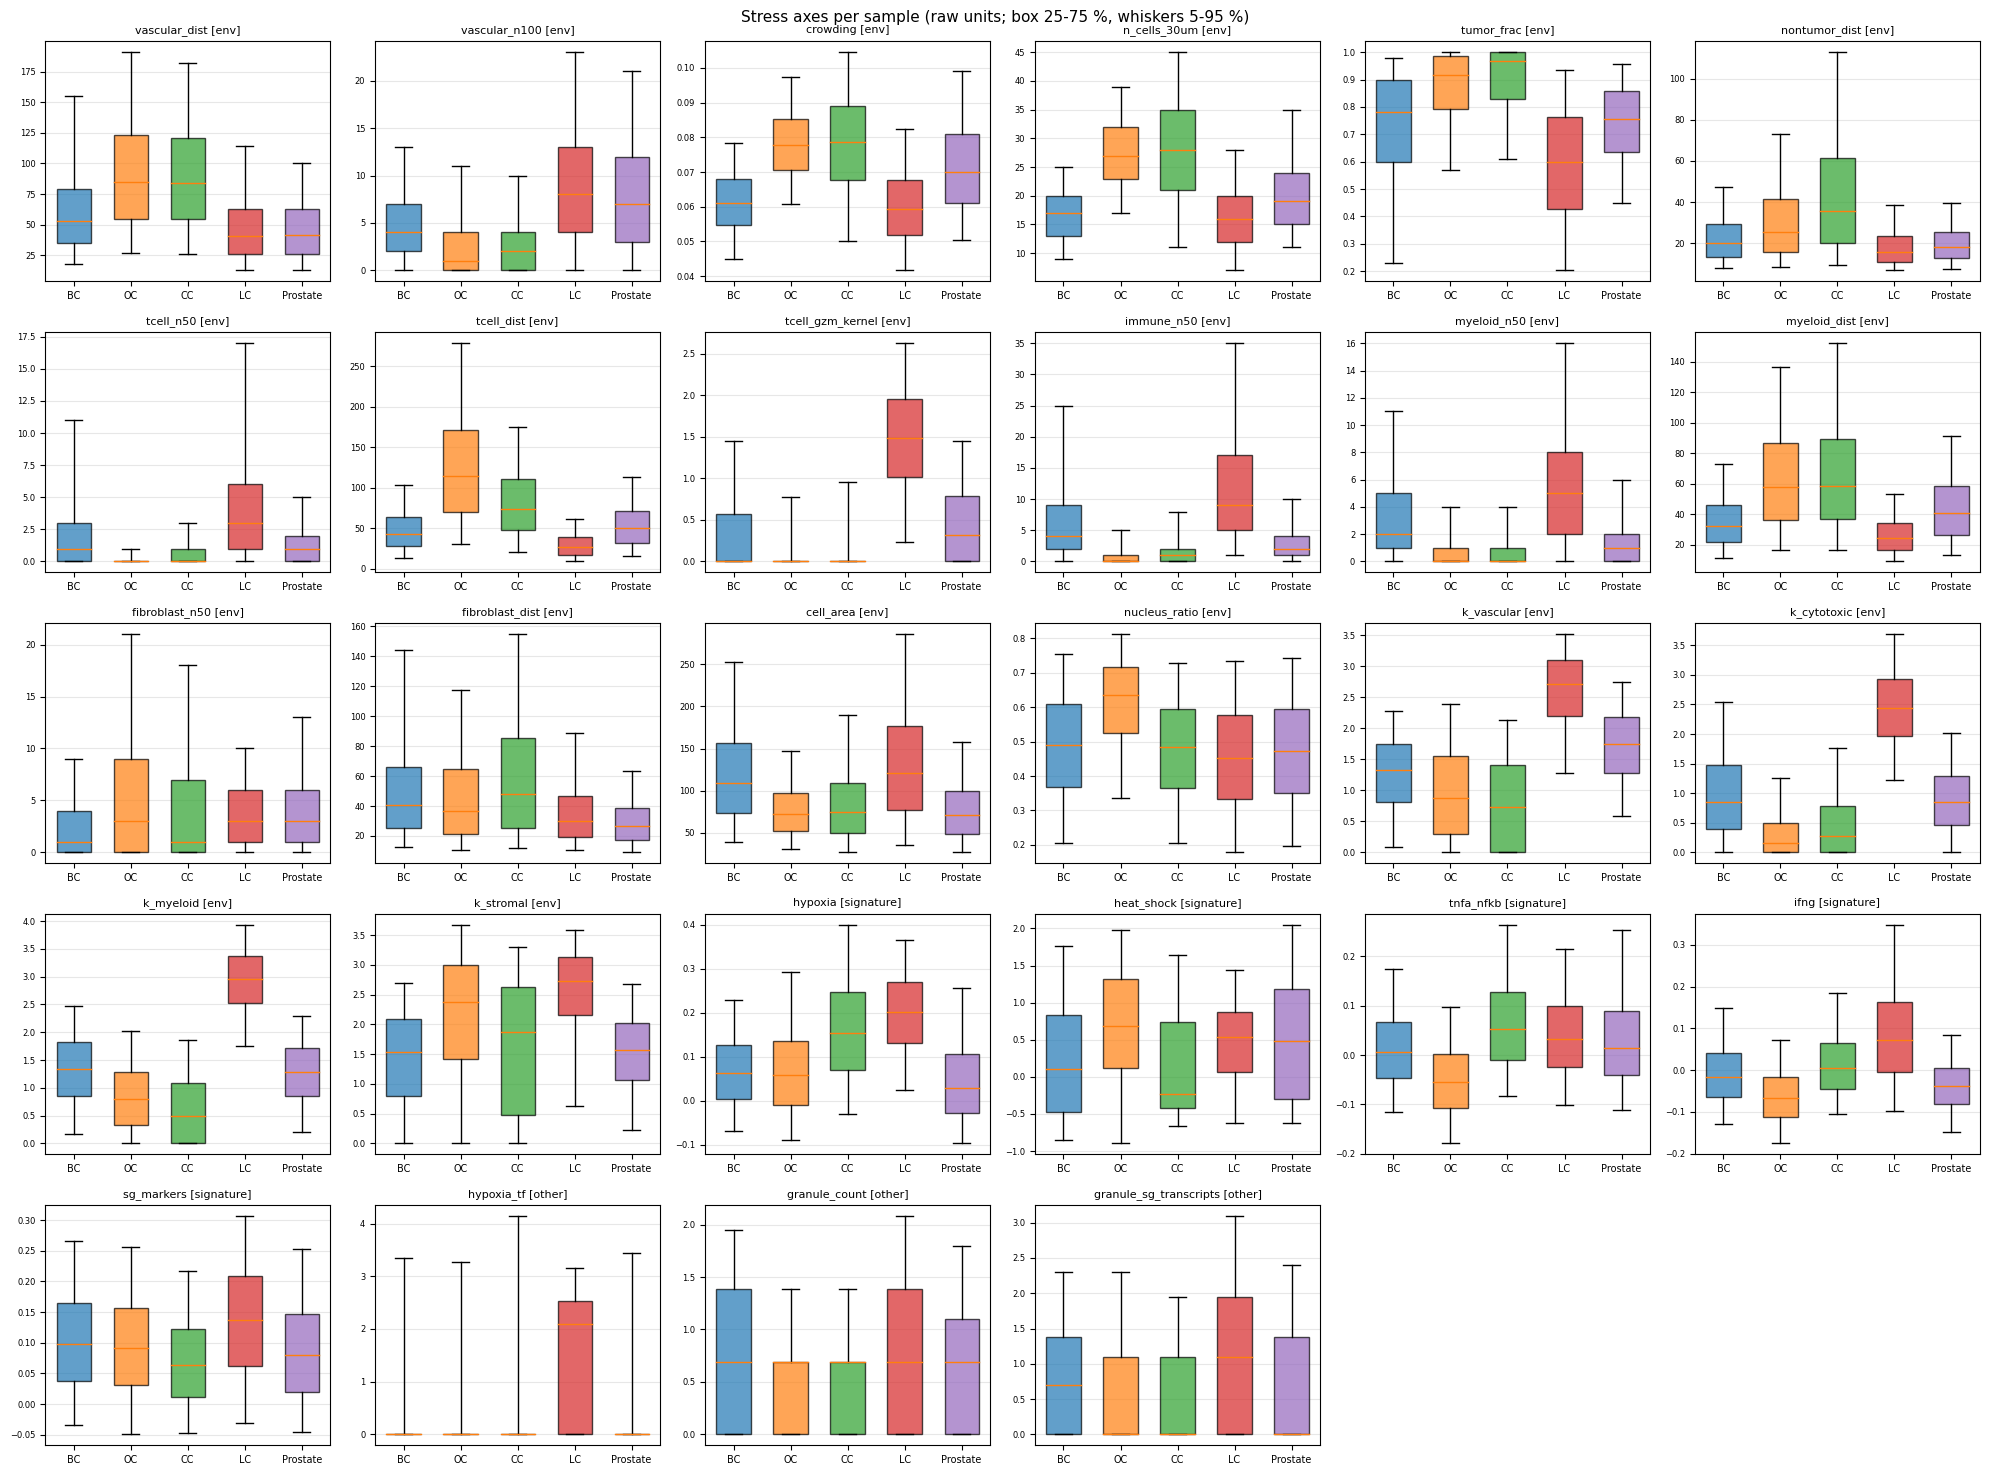

In [3]:
# Sanity checks on the stress table
assert SMOKE or len(stress) == 623838
nan_counts = {ax: int(stress[f"z_{ax}"].isna().sum()) for ax in AXES if stress[f"z_{ax}"].isna().any()}
print("axes with NaN cells (tumor_frac: no labelled neighbour within 50 um; nucleus_ratio: no nucleus area):", nan_counts)
assert set(nan_counts) <= {"tumor_frac", "nucleus_ratio"}, nan_counts
g = stress.groupby("sample")
print("\nLabel-free kernel vs label-based count (Spearman per sample):")
pairs = [("k_vascular", "vascular_n100"), ("k_cytotoxic", "tcell_n50"), ("k_myeloid", "myeloid_n50"), ("k_stromal", "fibroblast_n50")]
agree = pd.DataFrame({f"{a} vs {b}": [spearmanr(d[a], d[b]).correlation for s, d in g] for a, b in pairs}, index=[SHORT[s] for s, _ in g])
agree.to_csv(D["axes"] + "labelfree_vs_label_agreement.csv")
print(agree.round(2).to_string())
chk = pd.read_csv(CHAR["cyto"], usecols=["sample", "cell_id", "hypoxia_score_tf"])
chk["key"] = chk["sample"] + "|" + chk["cell_id"]
chk = chk.set_index("key").reindex(stress["key"])
print("\n8-TF hypoxia score vs the saved characteristics column: Spearman =", round(spearmanr(stress["hypoxia_tf"], chk["hypoxia_score_tf"]).correlation, 4))

sample_codes, sample_levels = pd.factorize(stress["sample"])
sample_levels = [SHORT[s] for s in sample_levels]
Z = stress[[f"z_{a}" for a in AX]].values.astype(np.float64)
Z_filled = np.where(np.isfinite(Z), Z, np.nanmedian(Z, axis=0))
XY = stress[["global_x", "global_y"]].values
print("spatial blocks:", stress["block"].nunique())
boot_idx = [su.block_resample(stress["block"].values, rng) for _ in range(B_BOOT)]
print(f"{B_BOOT} block-bootstrap resamples prepared")

# distributions of every axis per sample (raw units)
fig, axes = plt.subplots(5, 6, figsize=(20, 15))
for k, ax_ in enumerate(axes.ravel()):
    if k >= len(AX_ORDER):
        ax_.axis("off"); continue
    a = AX_ORDER[k]; v = stress[a].values.astype(float)
    bp = ax_.bxp([sf._box_stats(v[sample_codes == si]) for si in range(len(sample_levels))], positions=range(len(sample_levels)), showfliers=False, patch_artist=True, widths=0.6)
    for patch, s_ in zip(bp["boxes"], sample_levels):
        patch.set_facecolor(sf.SAMPLE_COLORS[s_]); patch.set_alpha(0.7)
    ax_.set_xticks(range(len(sample_levels))); ax_.set_xticklabels(sample_levels, fontsize=7); ax_.set_title(f"{a} [{AXIS_SET[a]}]", fontsize=8); ax_.tick_params(axis="y", labelsize=6); ax_.grid(alpha=0.3, axis="y")
fig.suptitle("Stress axes per sample (raw units; box 25-75 %, whiskers 5-95 %)", fontsize=11)
fig.tight_layout(); fig.savefig(D["axes"] + "axis_distributions_by_sample.png", dpi=150, bbox_inches="tight"); plt.show(); plt.close(fig)

## 1b. Composite stress scores and explicit stress subtypes

Composites = mean of the sign-aligned pooled z of the member axes, re-standardised. Two rule-based labellings of
every pooled cell, kept separate on purpose (environment = exposure, measured from the neighbourhood without any
transcript of the cell; expression = the cell's transcriptional response; see §4.1 of the plan document for why
they are not pooled into one clustering): `stress_env` = dominant environmental archetype (6 composites),
`stress_expr` = dominant expression archetype (hypoxia, heat shock, TNFA/NFKB, IFNG). A cell whose largest
composite is below 0.5 is "Unstressed". The cross-tab of the two labellings (which environments co-occur with
which responses) is an output in its own right.

sample                       BC     CC     LC     OC  Prostate    labelling  pooled
Core isolation             8046  70099    939  24057      3569   stress_env  106710
Crowding                    295  53450    155  27983     10012   stress_env   91895
Immune attack             19630   5618  22326   1825     14952   stress_env   64351
Myeloid contact           29574   7883  19006   8566     16402   stress_env   81431
Stromal contact            3989  40718   1074  50282      9966   stress_env  106029
Unstressed                25544   9246    471   9416     35526   stress_env   80203
Vascular deprivation      15102  34341    653  38121      5002   stress_env   93219
Heat shock                20996  28736   4234  64922     30757  stress_expr  149645
Hypoxia (expr)             6729  57784  13911  18563      4175  stress_expr  101162
Inflammatory (TNFA/NFKB)  13935  47028   3590   5103     19313  stress_expr   88969
Interferon (IFNG)         18148  39687  18947   8868      5360  stress_expr 


environment x response (log2 observed / expected, pooled):
                      Heat shock  Hypoxia (expr)  Inflammatory (TNFA/NFKB)  Interferon (IFNG)  Unstressed
Core isolation             -0.34            0.79                     -0.03              -0.07       -0.30
Crowding                    0.08           -0.14                     -0.34              -0.14        0.20
Immune attack              -0.37           -0.21                     -0.04               0.86       -0.19
Myeloid contact            -0.18           -0.25                      0.32               0.40       -0.13
Stromal contact             0.30           -0.58                      0.23              -0.58        0.09
Vascular deprivation        0.01            0.44                     -0.21              -0.13       -0.13
Unstressed                  0.27           -1.20                     -0.05              -0.46        0.36


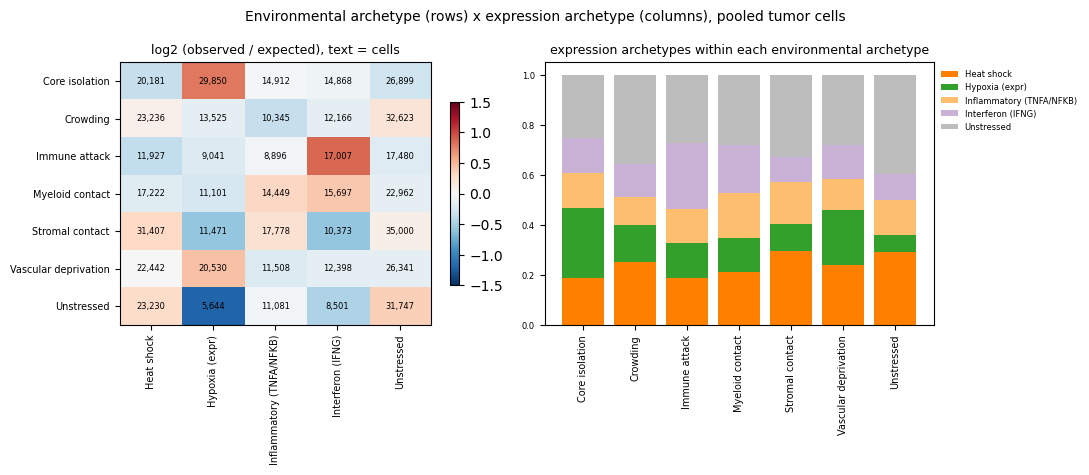

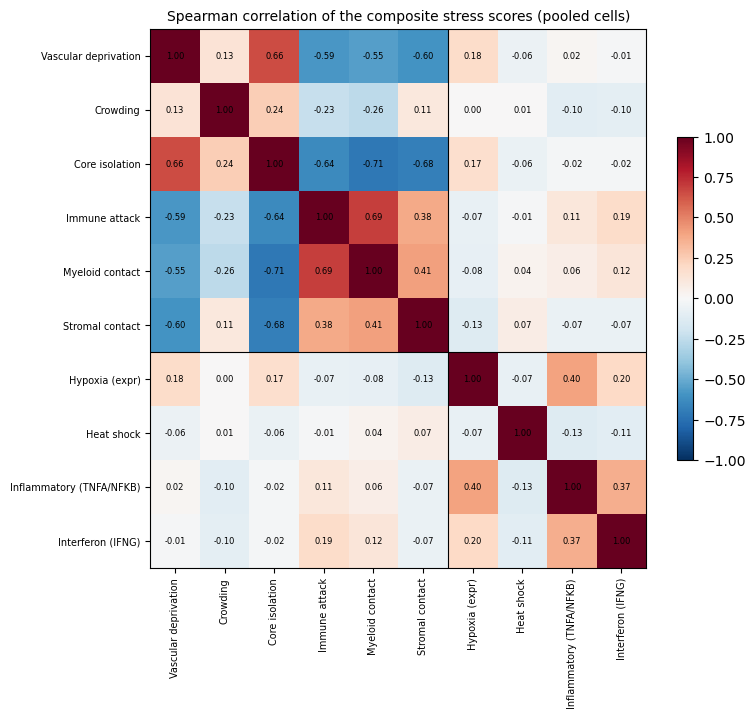

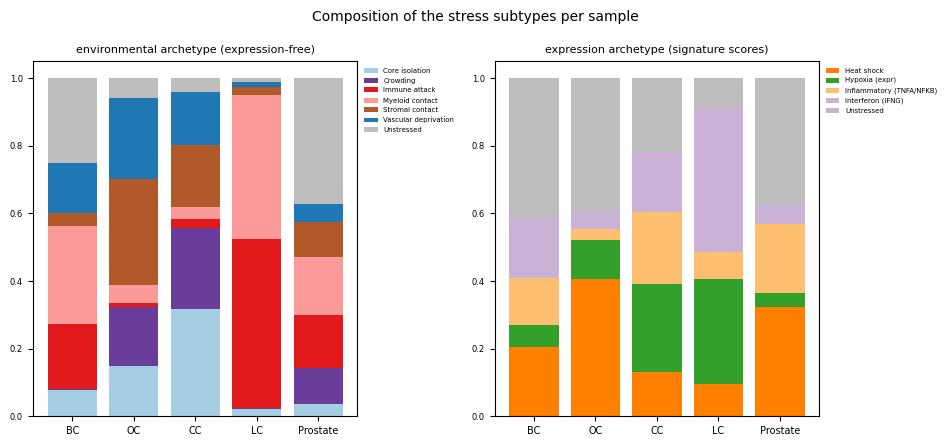

stress_axes figures written


In [4]:
comp_env = su.composite_scores(stress, su.COMPOSITES_ENV)
comp_expr = su.composite_scores(stress, su.COMPOSITES_EXPR)
STRESS = pd.DataFrame({"key": stress["key"].values, "sample": stress["sample"].values})
STRESS["stress_env"] = su.dominant_archetype(comp_env)
STRESS["stress_expr"] = su.dominant_archetype(comp_expr)
STRESS_LABELLINGS = ["stress_env", "stress_expr"]
STRESS_TITLES = {"stress_env": "environmental archetype (expression-free)", "stress_expr": "expression archetype (signature scores)"}
STRESS_SET = {"stress_env": "env", "stress_expr": "signature"}

comp_all = pd.concat([comp_env, comp_expr], axis=1)
comp_def = pd.DataFrame([{"composite": n, "tier": t, "members": "; ".join(f"{'+' if sg > 0 else '-'}{a}" for a, sg in m.items())}
                         for t, comps in [("env", su.COMPOSITES_ENV), ("expr", su.COMPOSITES_EXPR)] for n, m in comps.items()])
comp_def.to_csv(D["axes"] + "composites.csv", index=False)
pd.concat([STRESS, comp_all], axis=1).to_csv(D["axes"] + "stress_subtypes.csv", index=False)
sizes = pd.concat([pd.crosstab(STRESS[sl], STRESS["sample"].map(SHORT)).assign(labelling=sl) for sl in STRESS_LABELLINGS])
sizes["pooled"] = sizes[sample_levels].sum(axis=1)
sizes.to_csv(D["axes"] + "stress_subtype_sizes.csv")
print(sizes.to_string())

# environment x response: contingency of the two labellings, pooled and per sample
env_cats, expr_cats = sf.ordered(STRESS["stress_env"].values), sf.ordered(STRESS["stress_expr"].values)
ec = pd.Categorical(STRESS["stress_env"], categories=env_cats).codes; xc = pd.Categorical(STRESS["stress_expr"], categories=expr_cats).codes
tab, enr = su.enrichment_table(ec, len(env_cats), xc, len(expr_cats))
tab = pd.DataFrame(tab, index=env_cats, columns=expr_cats); enr = pd.DataFrame(enr, index=env_cats, columns=expr_cats)
rows_ee = []
for i, e in enumerate(env_cats):
    for j, x in enumerate(expr_cats):
        r = {"stress_env": e, "stress_expr": x, "n_cells": int(tab.iloc[i, j]), "pct_of_env": 100 * tab.iloc[i, j] / tab.iloc[i].sum(), "pct_of_expr": 100 * tab.iloc[i, j] / tab.iloc[:, j].sum(), "log2_enrichment": enr.iloc[i, j]}
        for si, sname in enumerate(sample_levels):
            ms = sample_codes == si
            _, e_s = su.enrichment_table(ec[ms], len(env_cats), xc[ms], len(expr_cats))
            r[f"log2_enrichment_{sname}"] = e_s[i, j]
        rows_ee.append(r)
env_expr = pd.DataFrame(rows_ee); env_expr.to_csv(D["axes"] + "stress_env_vs_expr.csv", index=False)
print(); print("environment x response (log2 observed / expected, pooled):"); print(enr.round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
im = axes[0].imshow(enr.values, cmap="RdBu_r", vmin=-1.5, vmax=1.5, aspect="auto")
for i in range(len(env_cats)):
    for j in range(len(expr_cats)):
        axes[0].text(j, i, f"{int(tab.iloc[i, j]):,}", ha="center", va="center", fontsize=6)
axes[0].set_xticks(range(len(expr_cats))); axes[0].set_xticklabels(expr_cats, rotation=90, fontsize=7); axes[0].set_yticks(range(len(env_cats))); axes[0].set_yticklabels(env_cats, fontsize=7)
axes[0].set_title("log2 (observed / expected), text = cells", fontsize=9); fig.colorbar(im, ax=axes[0], shrink=0.7)
share = tab.div(tab.sum(axis=1), axis=0); pal = sf.label_palette(expr_cats); bottom = np.zeros(len(env_cats))
for x in expr_cats:
    axes[1].bar(range(len(env_cats)), share[x].values, bottom=bottom, color=pal[x], label=x, width=0.8); bottom += share[x].values
axes[1].set_xticks(range(len(env_cats))); axes[1].set_xticklabels(env_cats, rotation=90, fontsize=7); axes[1].set_title("expression archetypes within each environmental archetype", fontsize=9)
axes[1].legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False); axes[1].tick_params(axis="y", labelsize=6)
fig.suptitle("Environmental archetype (rows) x expression archetype (columns), pooled tumor cells", fontsize=10)
fig.tight_layout(); fig.savefig(D["axes"] + "stress_env_vs_expr.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)
hl = {(0, e, x) for i, e in enumerate(env_cats) for j, x in enumerate(expr_cats) if enr.iloc[i, j] > 0.5}
sf.alluvial_figure([(STRESS_TITLES["stress_env"], STRESS["stress_env"].values), (STRESS_TITLES["stress_expr"], STRESS["stress_expr"].values)], D["axes"] + "sankey_env_vs_expr.png",
                   "Environmental archetype -> expression archetype of the pooled tumor cells (ribbon width = cells; opaque = log2 observed / expected > 0.5)", color_col=0, highlight=hl)

fig, ax = plt.subplots(figsize=(8, 7))
Rc = su.spearman_matrix(comp_all.values, comp_all.values)
im = sf.heatmap(ax, Rc, list(comp_all.columns), list(comp_all.columns), "Spearman correlation of the composite stress scores (pooled cells)", vmax=1.0, row_breaks=[6])
ax.axvline(5.5, color="k", lw=0.8)
for i in range(Rc.shape[0]):
    for j in range(Rc.shape[1]):
        ax.text(j, i, f"{Rc[i, j]:.2f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=ax, shrink=0.6); fig.savefig(D["axes"] + "composite_correlation.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, len(STRESS_LABELLINGS), figsize=(4.8 * len(STRESS_LABELLINGS), 4.5))
for ax_, sl in zip(axes, STRESS_LABELLINGS):
    cats = sf.ordered(STRESS[sl].values); pal = sf.label_palette(cats)
    share = pd.crosstab(STRESS["sample"].map(SHORT), pd.Categorical(STRESS[sl], categories=cats), normalize="index").reindex(sample_levels)
    bottom = np.zeros(len(sample_levels))
    for c in cats:
        ax_.bar(range(len(sample_levels)), share[c].values, bottom=bottom, color=pal[c], label=c, width=0.8); bottom += share[c].values
    ax_.set_xticks(range(len(sample_levels))); ax_.set_xticklabels(sample_levels, fontsize=7); ax_.set_title(STRESS_TITLES[sl], fontsize=8)
    ax_.legend(fontsize=5, loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False); ax_.tick_params(axis="y", labelsize=6)
fig.suptitle("Composition of the stress subtypes per sample", fontsize=10)
fig.tight_layout(); fig.savefig(D["axes"] + "stress_subtype_composition_by_sample.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

KEY_AXES = ["vascular_dist", "crowding", "tumor_frac", "k_cytotoxic", "hypoxia", "ifng"]
for si, sname in enumerate(sample_levels):
    m = sample_codes == si
    sf.spatial_axes_figure(stress, {a: AXIS_TITLES[a] for a in KEY_AXES}, m, f"{sname}: key stress axes (tumor cells)", D["axes"] + f"spatial_axes_{sname}.png")
    sf.spatial_labels_figure(stress, {STRESS_TITLES[sl]: STRESS[sl].values for sl in STRESS_LABELLINGS}, m, f"{sname}: stress subtypes of the tumor cells", D["axes"] + f"spatial_stress_subtypes_{sname}.png")
print("stress_axes figures written")

## 2. Join with the substate labellings, program scores, PCs and graphs

In [5]:
labels, scores, depth = {}, {}, {}
for comp in ["cyto", "nuc"]:
    ann = pd.read_csv(POOLED[comp] + "annotation/cell_subtypes_pooled.csv", usecols=["sample", "cell_id", "subtype_louvain_pooled", "subtype_label_pooled"])
    ann["key"] = ann["sample"] + "|" + ann["cell_id"]
    ann = ann.set_index("key").reindex(stress["key"])
    assert ann["subtype_label_pooled"].notna().all()
    labels[comp] = ann[["subtype_louvain_pooled", "subtype_label_pooled"]].rename(columns={"subtype_louvain_pooled": "cluster", "subtype_label_pooled": "label"}).reset_index(drop=True)
    ch = pd.read_csv(CHAR[comp], low_memory=False)
    ch["key"] = ch["sample"] + "|" + ch["cell_id"]
    ch = ch.set_index("key").reindex(stress["key"])
    score_cols = [c for c in ch.columns if c.startswith("score_")]
    scores[comp] = ch[score_cols].reset_index(drop=True)
    depth[comp] = ch["cyto_target_counts"].values            # target-gene transcripts of this compartment (column name is historical)
    print(f"{COMP_NAME[comp]}: labels {labels[comp]['label'].nunique()}, clusters {labels[comp]['cluster'].nunique()}, program scores {len(score_cols)}")
    print("   ", labels[comp]["label"].value_counts().to_dict())

PCS, GRAPH = {}, {}
for comp in ["cyto", "nuc"]:
    with h5py.File(OBJ[comp]) as f:
        PCS[comp] = su.standardize(f["obsm/X_pca"][...].astype(np.float64))
        GRAPH[comp] = read_elem(f["obsp/connectivities"]).tocsr()
    if SEL is not None:
        PCS[comp], GRAPH[comp] = PCS[comp][SEL], GRAPH[comp][SEL][:, SEL]
PCS["joint"] = np.hstack([PCS["cyto"], PCS["nuc"]])
print("PCs:", {k: v.shape for k, v in PCS.items()}, "graph nnz:", {k: v.nnz for k, v in GRAPH.items()})

cytoplasmic: labels 11, clusters 16, program scores 23
    {'Baseline': 122518, 'S-phase': 88290, 'Hypoxia': 88264, 'ER stress': 75564, 'G2/M': 57030, 'Stress response': 52847, 'Stroma border': 43336, 'Interferon': 32990, 'Complement / acute phase': 22902, 'Myeloid border': 22588, 'Low depth': 17509}


nuclear: labels 12, clusters 21, program scores 23
    {'Baseline': 188495, 'Hypoxia': 72172, 'S-phase': 60038, 'G2/M': 59924, 'Low depth': 52847, 'Interferon': 51879, 'EMT/stroma': 49741, 'ER stress': 29448, 'Cholesterol synthesis': 28282, 'Complement / acute phase': 12654, 'Stress response': 12313, 'Myeloid border': 6045}


PCs: {'cyto': (623838, 50), 'nuc': (623838, 50), 'joint': (623838, 100)} graph nnz: {'cyto': 33982942, 'nuc': 33376424}


## 3. Per-compartment analysis (question a), written to `cytoplasmic/` and `nuclear/`

Approach 1: **A** stress profile of the substates (median z per axis, R2 beyond sample with block-bootstrap CI,
epsilon2) and **B** stress groups (tertiles / Away-Close) vs substates (Cramer's V, AMI, log2 odds ratios pooled,
Mantel-Haenszel and per sample; reproducible = |log2 OR| > 0.5, CI excludes 0, same sign in >= 3 of 5 samples).
Approach 2: substates vs each explicit stress labelling (contingency table, log2 enrichment with the same
reproducibility rule, Cramer's V and AMI with CIs). **D** program scores vs axes. Then the intuitive figures and
the folder summary. Low depth cells are dropped; Stroma border and Myeloid border are dropped from the axes that
define them.

In [6]:
def subset_boot(keep):
    pos = np.full(len(stress), -1); pos[np.where(keep)[0]] = np.arange(keep.sum())
    out = []
    for idx in boot_idx:
        i = pos[idx]; out.append(i[i >= 0])
    return out

R = {}        # results per compartment
for comp in ["cyto", "nuc"]:
    t0 = time.time()
    out, cname = D[comp], COMP_NAME[comp]
    lab = labels[comp]["label"].values.astype(object); clu = labels[comp]["cluster"].values
    keep = lab != "Low depth"
    lab_codes, lab_levels = pd.factorize(lab[keep]); lab_levels = list(lab_levels)
    label_order = [l for l in sf.LABEL_ORDER if l in lab_levels]
    bk = subset_boot(keep)
    sc_k = sample_codes[keep]
    res = {"label_order": label_order, "keep": keep}

    # ---------------- A: profile
    df = pd.DataFrame(Z[keep], columns=AX); df["label"] = lab[keep]
    med = df.groupby("label")[AX].median().T.reindex(AX_ORDER)[label_order]
    share_high = pd.DataFrame({l: [np.mean(stress.loc[keep & (lab == l), f"grp_{a}"].values == top_low(a)[0]) for a in AX_ORDER] for l in label_order}, index=AX_ORDER)
    r2 = su.r2_beyond_sample(Z_filled[keep], sc_k, lab_codes)
    r2_boot = np.array([su.r2_beyond_sample(Z_filled[keep][idx], sc_k[idx], lab_codes[idx]) for idx in bk])
    eps = np.array([su.epsilon2(Z[keep][:, j], lab_codes) for j in range(len(AX))])
    prof = med.copy()
    pos_ax = {a: j for j, a in enumerate(AX)}
    prof.insert(0, "axis_set", [AXIS_SET[a] for a in AX_ORDER])
    prof.insert(1, "r2_beyond_sample", [r2[pos_ax[a]] for a in AX_ORDER])
    prof.insert(2, "r2_ci_low", [np.percentile(r2_boot[:, pos_ax[a]], 2.5) for a in AX_ORDER])
    prof.insert(3, "r2_ci_high", [np.percentile(r2_boot[:, pos_ax[a]], 97.5) for a in AX_ORDER])
    prof.insert(4, "epsilon2", [eps[pos_ax[a]] for a in AX_ORDER])
    prof.to_csv(out + "profile.csv")
    res.update(profile=prof, r2_boot=pd.DataFrame(r2_boot, columns=AX), med=med, share_high=share_high)

    # ---------------- B: groups vs labels
    ax_rows, lab_rows = [], []
    for a in AX_ORDER:
        grp = stress[f"grp_{a}"].values
        top, low = top_low(a)
        m = keep & np.isin(grp, [top, low])
        excl = [l for l, axes_ in su.LABEL_AXIS_EXCLUSIONS.items() if a in axes_]
        if excl:
            m &= ~np.isin(lab, excl)
        high = grp[m] == top
        lc, ll = pd.factorize(lab[m]); ll = list(ll)
        cc = pd.factorize(clu[m])[0]
        ax_rows.append({"axis": a, "axis_set": AXIS_SET[a], "n_cells": int(m.sum()), "excluded_labels": ";".join(excl),
                        "cramers_v_label": su.cramers_v(lc, high), "ami_label": su.ami(lc, high),
                        "cramers_v_cluster": su.cramers_v(cc, high), "ami_cluster": su.ami(cc, high)})
        pooled_or = su.log2_or_table(lc, high, len(ll))
        mh = su.mantel_haenszel_log2_or(lc, high, sample_codes[m], len(ll))
        per_s = np.full((len(ll), len(sample_levels)), np.nan)
        for si in range(len(sample_levels)):
            ms = sample_codes[m] == si
            if ms.sum() > 0 and high[ms].sum() > 0 and (~high[ms]).sum() > 0:
                per_s[:, si] = su.log2_or_table(lc[ms], high[ms], len(ll))
        bm = subset_boot(m)
        boots = np.array([su.log2_or_table(lc[idx], high[idx], len(ll)) for idx in bm])
        lo, hi = np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)
        for k, l in enumerate(ll):
            same = int(np.sum(np.sign(per_s[k][np.isfinite(per_s[k])]) == np.sign(pooled_or[k])))
            lab_rows.append({"axis": a, "axis_set": AXIS_SET[a], "label": l, "high_group": top, "log2_or_pooled": pooled_or[k], "ci_low": lo[k], "ci_high": hi[k], "log2_or_mh": mh[k],
                             **{f"log2_or_{sample_levels[si]}": per_s[k, si] for si in range(len(sample_levels))},
                             "n_samples_same_sign": same, "reproducible": bool(abs(pooled_or[k]) > 0.5 and same >= 3 and (lo[k] > 0 or hi[k] < 0))})
    corr_axis = pd.DataFrame(ax_rows).set_index("axis"); corr_label = pd.DataFrame(lab_rows)
    corr_axis.to_csv(out + "correspondence_axes.csv"); corr_label.to_csv(out + "correspondence_labels.csv", index=False)
    res.update(corr_axis=corr_axis, corr_label=corr_label)

    # ---------------- approach 2: explicit stress subtypes vs substates
    conts, longs, srows = {}, [], []
    for sl in STRESS_LABELLINGS:
        b = STRESS[sl].values.astype(object)
        cont, long, smm = su.label_correspondence(lab[keep], b[keep], bk, sc_k, sample_levels)
        cont = cont.reindex(index=label_order, columns=sf.ordered(b[keep]))
        cont.to_csv(out + f"contingency_{sl}.csv")
        long.insert(0, "stress_labelling", sl); longs.append(long); conts[sl] = (cont, long)
        strongest = long[long["reproducible"]].reindex(long[long["reproducible"]]["log2_enrichment"].abs().sort_values(ascending=False).index).head(1)
        srows.append({"stress_labelling": sl, "axis_set": STRESS_SET[sl], "n_stress_subtypes": cont.shape[1],
                      "cramers_v": smm["cramers_v"], "v_ci_low": smm["v_ci_low"], "v_ci_high": smm["v_ci_high"],
                      "ami": smm["ami"], "ami_ci_low": smm["ami_ci_low"], "ami_ci_high": smm["ami_ci_high"],
                      "cramers_v_cluster": su.cramers_v(clu[keep], b[keep]), "ami_cluster": su.ami(clu[keep], b[keep]),
                      "n_reproducible": smm["n_reproducible"],
                      "strongest_pair": "" if strongest.empty else f"{strongest['substate'].iloc[0]} x {strongest['stress_subtype'].iloc[0]} (log2 enr {strongest['log2_enrichment'].iloc[0]:+.2f})",
                      "_v_boot": smm["v_boot"], "_ami_boot": smm["ami_boot"]})
    stress_long = pd.concat(longs, ignore_index=True); stress_long.to_csv(out + "stress_subtype_correspondence.csv", index=False)
    stress_summ = pd.DataFrame(srows)
    stress_summ.drop(columns=["_v_boot", "_ami_boot"]).to_csv(out + "stress_subtype_summary.csv", index=False)
    res.update(conts=conts, stress_long=stress_long, stress_summ=stress_summ)

    # ---------------- signal strength (question a) per approach x axis set
    sig = []
    for vname, axset in AXSETS:
        ca = corr_axis.loc[axset]; cl = corr_label[corr_label["axis"].isin(axset)]
        rep = cl[cl["reproducible"]]
        best = rep.reindex(rep["log2_or_pooled"].abs().sort_values(ascending=False).index).head(1)
        sig.append({"approach": "1: stress groups across substates", "axis_set": vname, "n_items": len(axset),
                    "max_V": ca["cramers_v_label"].max(), "median_V": ca["cramers_v_label"].median(), "max_AMI": ca["ami_label"].max(), "median_AMI": ca["ami_label"].median(),
                    "max_R2_beyond_sample": prof.loc[axset, "r2_beyond_sample"].max(), "median_R2_beyond_sample": prof.loc[axset, "r2_beyond_sample"].median(),
                    "n_reproducible": int(len(rep)), "strongest": "" if best.empty else f"{best['label'].iloc[0]} x {best['axis'].iloc[0]} (log2 OR {best['log2_or_pooled'].iloc[0]:+.2f})"})
    for _, r in stress_summ.iterrows():
        sig.append({"approach": "2: explicit stress subtypes", "axis_set": r["stress_labelling"], "n_items": 1,
                    "max_V": r["cramers_v"], "median_V": r["cramers_v"], "max_AMI": r["ami"], "median_AMI": r["ami"], "max_R2_beyond_sample": np.nan, "median_R2_beyond_sample": np.nan,
                    "n_reproducible": r["n_reproducible"], "strongest": r["strongest_pair"]})
    sig = pd.DataFrame(sig); sig.to_csv(out + "signal_strength.csv", index=False)
    res["signal"] = sig

    # ---------------- D: program scores vs axes
    S = scores[comp].values.astype(np.float64); prog_names = [c.replace("score_", "") for c in scores[comp].columns]
    Dm = {"pooled": su.spearman_matrix(S, Z, None), "partial": su.spearman_matrix(S, Z, sample_codes)}
    for si, sname in enumerate(sample_levels):
        ms = sample_codes == si; Dm[sname] = su.spearman_matrix(S[ms], Z[ms], None)
    prow = []
    for i, p in enumerate(prog_names):
        for a in AX_ORDER:
            j = pos_ax[a]
            prow.append({"program": p, "axis": a, "axis_set": AXIS_SET[a], "rho_pooled": Dm["pooled"][i, j], "rho_partial": Dm["partial"][i, j], **{f"rho_{s}": Dm[s][i, j] for s in sample_levels}})
    prog = pd.DataFrame(prow); prog.to_csv(out + "program_correlation.csv", index=False)
    res.update(prog=prog, prog_names=prog_names, Dpartial=Dm["partial"])
    print(f"{cname}: A, B, approach 2, D done in {time.time() - t0:.0f} s; reproducible pairs approach 1: {int(corr_label['reproducible'].sum())}, approach 2: {stress_summ['n_reproducible'].tolist()}")
    R[comp] = res

for comp in ["cyto", "nuc"]:
    print("=" * 30, COMP_NAME[comp], "=" * 30)
    print(R[comp]["signal"].round(3).to_string())

cytoplasmic: A, B, approach 2, D done in 119 s; reproducible pairs approach 1: 102, approach 2: [17, 20]


nuclear: A, B, approach 2, D done in 111 s; reproducible pairs approach 1: 109, approach 2: [13, 15]
============================== cytoplasmic ==============================
                            approach     axis_set  n_items  max_V  median_V  max_AMI  median_AMI  max_R2_beyond_sample  median_R2_beyond_sample  n_reproducible                                        strongest
0  1: stress groups across substates          env       20  0.338     0.233    0.042       0.020                 0.082                    0.035              80       Stroma border x tumor_frac (log2 OR -2.43)
1  1: stress groups across substates    signature        5  0.398     0.299    0.059       0.034                 0.115                    0.072              22                Interferon x ifng (log2 OR +3.30)
2        2: explicit stress subtypes   stress_env        1  0.152     0.152    0.032       0.032                   NaN                      NaN              17  Stroma border x Core isolation (log2 

In [7]:
# Per-compartment figures
HEADLINE_PAIRS = [("Hypoxia", "vascular_dist"), ("Interferon", "k_cytotoxic"), ("Stress response", "crowding")]
BOX_AXES = ["vascular_dist", "vascular_n100", "n_cells_30um", "tumor_frac", "tcell_n50", "k_cytotoxic", "fibroblast_dist", "cell_area",
            "hypoxia", "ifng", "tnfa_nfkb", "heat_shock", "sg_markers", "granule_count", "granule_sg_transcripts"]   # granule-level scores shown, not used for subtyping
for comp in ["cyto", "nuc"]:
    t0 = time.time()
    out, cname, res = D[comp], COMP_NAME[comp], R[comp]
    lab = labels[comp]["label"].values.astype(object); keep = res["keep"]; label_order = res["label_order"]
    prof, corr_label, med, share_high = res["profile"], res["corr_label"], res["med"], res["share_high"]

    # A/B heatmaps (axes in rows: env | signature | other)
    fig, ax = plt.subplots(figsize=(0.55 * len(label_order) + 4, 10))
    im = sf.heatmap(ax, med.values, [f"{a} [{AXIS_SET[a]}]" for a in AX_ORDER], label_order, f"{cname} substates: median pooled z of each stress axis", vmax=1.0, row_breaks=ROW_BREAKS)
    for i, a in enumerate(AX_ORDER):
        ax.text(len(label_order) - 0.4, i, f"R2 {prof.loc[a, 'r2_beyond_sample']:.3f}", fontsize=5, va="center")
    fig.colorbar(im, ax=ax, shrink=0.5, label="median z (pooled)")
    fig.savefig(out + "profile_heatmap.png", dpi=200, bbox_inches="tight"); plt.close(fig)

    piv = corr_label.pivot(index="axis", columns="label", values="log2_or_pooled").reindex(index=AX_ORDER, columns=label_order)
    fig, ax = plt.subplots(figsize=(0.55 * len(label_order) + 4, 10))
    im = sf.heatmap(ax, piv.values, [f"{a} [{AXIS_SET[a]}]" for a in AX_ORDER], label_order, f"{cname} substates: log2 OR of the High / Close group", vmax=2.0, row_breaks=ROW_BREAKS)
    fig.colorbar(im, ax=ax, shrink=0.5, label="log2 odds ratio")
    fig.savefig(out + "odds_ratio_heatmap.png", dpi=200, bbox_inches="tight"); plt.close(fig)

    sf.dotplot_figure(med, share_high, out + "dotplot_substate_axes.png", f"{cname} substates: median z (colour) and share of cells in the High / Close group (size)")
    sf.boxplot_axes_figure(stress[keep], lab[keep], sample_codes[keep], sample_levels, {a: AXIS_TITLES[a] for a in BOX_AXES}, out + "boxplot_axes_by_substate.png", label_order)
    sf.stacked_groups_figure(stress[keep], lab[keep], AX_ENV + AX_SIG, {a: grp_names(a) for a in AX}, out + "stacked_groups_by_substate.png", label_order)

    # approach 2 figures
    sf.enrichment_heatmaps([(STRESS_TITLES[sl], res["conts"][sl][0], res["conts"][sl][1]) for sl in STRESS_LABELLINGS], out + "stress_subtype_enrichment.png",
                           f"{cname} substates vs explicit stress subtypes: log2 (observed / expected), text = cell counts")
    sf.composition_figure([(STRESS_TITLES[sl], lab[keep], STRESS[sl].values[keep]) for sl in STRESS_LABELLINGS],
                          out + "stress_subtype_composition.png", f"{cname} substates and stress archetypes")
    hl = set()
    for k, sl in [(0, "stress_env"), (1, "stress_expr")]:
        lg = res["conts"][sl][1]; lg = lg[lg["reproducible"] & (lg["log2_enrichment"] > 0)]
        for _, r in lg.iterrows():
            hl.add((0, r["stress_subtype"], r["substate"]) if k == 0 else (1, r["substate"], r["stress_subtype"]))
    sf.alluvial_figure([(STRESS_TITLES["stress_env"], STRESS["stress_env"].values[keep]), (f"{cname} substates", lab[keep]), (STRESS_TITLES["stress_expr"], STRESS["stress_expr"].values[keep])],
                       out + "sankey_substates_vs_stress.png", f"{cname} substates between the environmental (left) and expression (right) archetypes; ribbon width = cells, opaque = reproducibly enriched pair", color_col=1, highlight=hl)

    # spatial maps
    for sub, a in HEADLINE_PAIRS:
        if sub in label_order:
            sf.spatial_pair_figure(stress, lab, sample_levels, sample_codes, (sub, a), AXIS_TITLES[a], out + f"spatial_{sub.replace(' ', '_').replace('/', '-')}_vs_{a}.png")
    for si, sname in enumerate(sample_levels):
        m = sample_codes == si
        cols = {f"{cname} substates": lab}
        cols.update({STRESS_TITLES[sl]: STRESS[sl].values for sl in STRESS_LABELLINGS})
        sf.spatial_labels_figure(stress, cols, m, f"{sname}: {cname} substates next to the stress subtypes", out + f"spatial_labels_vs_stress_{sname}.png")

    # forest plot of the strongest reproducible (substate, axis) pairs (env + signature axes)
    cl = corr_label[corr_label["axis"].isin(AX_ENV + AX_SIG) & corr_label["reproducible"]].copy()
    cl["name"] = cl["label"] + "  x  " + cl["axis"] + " (" + cl["high_group"] + ")"
    cl = cl.reindex(cl["log2_or_pooled"].abs().sort_values(ascending=False).index).head(16)
    sf.forest_figure(cl, sample_levels, out + "forest_headline.png", f"{cname} substates: strongest reproducible associations (pooled and per sample)")

    # D figures
    fig, ax = plt.subplots(figsize=(13, 7))
    Dp = res["Dpartial"][:, [AX.index(a) for a in AX_ORDER]]
    im = sf.heatmap(ax, Dp, res["prog_names"], [f"{a} [{AXIS_SET[a]}]" for a in AX_ORDER], f"{cname} program scores vs stress axes (partial Spearman given sample)", vmax=0.4)
    for rb in ROW_BREAKS:
        ax.axvline(rb - 0.5, color="k", lw=0.8)
    fig.colorbar(im, ax=ax, shrink=0.6, label="Spearman rho"); fig.savefig(out + "program_axis_heatmap.png", dpi=200, bbox_inches="tight"); plt.close(fig)
    print(f"{cname}: figures written in {time.time() - t0:.0f} s")

cytoplasmic: figures written in 37 s


nuclear: figures written in 38 s


In [8]:
# Per-compartment summaries (question a)
def summarize_compartment(comp):
    res, cname = R[comp], COMP_NAME[comp]
    L = [f"{cname.upper()} target-gene substates vs tumor stress (question a); pooled cells of BC/OC/CC/LC/Prostate, Low depth excluded (n = {int(res['keep'].sum()):,})", ""]
    L.append("Approach 1: stress groups across substates (profile.csv, correspondence_*.csv)")
    for vname, axset in [("env (20 expression-free axes)", AX_ENV), ("signature (5 whole-cell signature scores)", AX_SIG), ("other (8-TF rule, granule burden)", AX_OTHER)]:
        ca = res["corr_axis"].loc[axset]; pr = res["profile"].loc[axset]
        L.append(f"  {vname}: median / max Cramer's V {ca['cramers_v_label'].median():.3f} / {ca['cramers_v_label'].max():.3f}; median / max AMI {ca['ami_label'].median():.3f} / {ca['ami_label'].max():.3f}; "
                 f"median / max R2 beyond sample {pr['r2_beyond_sample'].median():.3f} / {pr['r2_beyond_sample'].max():.3f}")
    rep = res["corr_label"][res["corr_label"]["reproducible"]]
    L.append(f"  reproducible (substate, axis) pairs: {len(rep)} (env {int(rep['axis_set'].eq('env').sum())}, signature {int(rep['axis_set'].eq('signature').sum())}, other {int(rep['axis_set'].eq('other').sum())}); strongest 20:")
    for _, r in rep.reindex(rep["log2_or_pooled"].abs().sort_values(ascending=False).index).head(20).iterrows():
        L.append(f"     {r['label']:>24s} x {r['axis']:<22s} [{r['axis_set']:>9s}] log2 OR {r['log2_or_pooled']:+.2f} (MH {r['log2_or_mh']:+.2f}, same sign in {r['n_samples_same_sign']}/5)")
    L.append("  per substate, reproducible associations with the expression-free axes:")
    for l in res["label_order"]:
        rr = rep[(rep["label"] == l) & (rep["axis_set"] == "env")].sort_values("log2_or_pooled", key=np.abs, ascending=False)
        if len(rr):
            L.append(f"     {l:>24s}: " + ", ".join(f"{a} {o:+.1f}" for a, o in zip(rr["axis"], rr["log2_or_pooled"])))
    L.append("")
    L.append("Approach 2: explicit stress subtypes vs substates (contingency_*.csv, stress_subtype_correspondence.csv)")
    for _, r in res["stress_summ"].iterrows():
        L.append(f"  {r['stress_labelling']:<24s} ({r['n_stress_subtypes']} subtypes): Cramer's V {r['cramers_v']:.3f} [{r['v_ci_low']:.3f}, {r['v_ci_high']:.3f}], AMI {r['ami']:.3f} [{r['ami_ci_low']:.3f}, {r['ami_ci_high']:.3f}], "
                 f"{r['n_reproducible']} reproducible cells; strongest: {r['strongest_pair']}")
    for sl in STRESS_LABELLINGS:
        lg = res["stress_long"]; lg = lg[(lg["stress_labelling"] == sl) & lg["reproducible"] & (lg["log2_enrichment"] > 0)]
        L.append(f"  {sl}: enriched pairs (substate -> stress subtype, log2 enrichment, % of the substate's cells): " +
                 "; ".join(f"{r['substate']} -> {r['stress_subtype']} {r['log2_enrichment']:+.2f} ({r['pct_of_substate']:.0f} %)" for _, r in lg.sort_values('log2_enrichment', ascending=False).head(8).iterrows()))
    L.append("")
    sig = res["signal"]
    best1 = sig[sig["approach"].str.startswith("1")].sort_values("max_AMI", ascending=False).iloc[0]
    best2 = sig[sig["approach"].str.startswith("2")].sort_values("max_AMI", ascending=False).iloc[0]
    best = sig.sort_values("max_AMI", ascending=False).iloc[0]
    L.append("Strongest signal (by AMI with the substates; Cramer's V in brackets):")
    L.append(f"  approach 1 best axis set: {best1['axis_set']} (AMI {best1['max_AMI']:.3f} [V {best1['max_V']:.3f}], {best1['strongest']})")
    L.append(f"  approach 2 best labelling: {best2['axis_set']} (AMI {best2['max_AMI']:.3f} [V {best2['max_V']:.3f}], {best2['strongest']})")
    L.append(f"  overall: approach {best['approach']} / {best['axis_set']}")
    L.append("  (signatures use their canonical gene lists; the minus-634 arm was retired on 2026-11-08 after the review run showed it weaker on every metric, see plans/stress_substate_exploration.md)")
    return "\n".join(L)

for comp in ["cyto", "nuc"]:
    txt = summarize_compartment(comp)
    open(D[comp] + "summary.txt", "w").write(txt + "\n")
    print(txt); print()

CYTOPLASMIC target-gene substates vs tumor stress (question a); pooled cells of BC/OC/CC/LC/Prostate, Low depth excluded (n = 606,329)

Approach 1: stress groups across substates (profile.csv, correspondence_*.csv)
  env (20 expression-free axes): median / max Cramer's V 0.233 / 0.338; median / max AMI 0.020 / 0.042; median / max R2 beyond sample 0.035 / 0.082
  signature (5 whole-cell signature scores): median / max Cramer's V 0.299 / 0.398; median / max AMI 0.034 / 0.059; median / max R2 beyond sample 0.072 / 0.115
  other (8-TF rule, granule burden): median / max Cramer's V 0.129 / 0.131; median / max AMI 0.006 / 0.006; median / max R2 beyond sample 0.006 / 0.008
  reproducible (substate, axis) pairs: 102 (env 80, signature 22, other 0); strongest 20:
                   Interferon x ifng                   [signature] log2 OR +3.30 (MH +3.46, same sign in 5/5)
                      Hypoxia x hypoxia                [signature] log2 OR +2.78 (MH +3.07, same sign in 5/5)
               

## 4. Comparison of the compartments (question b), written to `comparison/`

**C** information content: ridge regression of each axis on the 50 sample-corrected PCs of each compartment (and
both jointly), out-of-fold predictions from 5 spatial-block folds and from leave-one-sample-out; R2 and AUROC of
the High vs Low group; the same with every axis standardised within sample (block folds only); depth strata;
Moran's I on the 30-NN expression graphs. Then the side-by-side correspondence statistics of approaches 1 and 2,
the signal-strength scoreboard, paired Sankey flows and paired spatial maps.

In [9]:
folds_block = su.block_folds(stress["block"].values, N_FOLDS, rng)
folds_loso = sample_codes.copy()
nuc_depth = depth["nuc"]
dec = pd.qcut(pd.Series(nuc_depth).rank(method="first"), 10, labels=False).values
Z_ws = su.within_sample_z(stress, AX, sample_codes)
info_rows, depth_rows, ws_rows = [], [], []
t0 = time.time()
for j, a in enumerate(AX):
    y = Z[:, j]
    top, low = top_low(a)
    grp = stress[f"grp_{a}"].values
    yb = np.where(grp == top, 1.0, np.where(grp == low, 0.0, np.nan))
    for feat in ["cyto", "nuc", "joint"]:
        for scheme, folds in [("blockCV", folds_block), ("LOSO", folds_loso)]:
            p = su.cv_predictions(PCS[feat], y, folds)
            row = {"axis": a, "axis_set": AXIS_SET[a], "features": feat, "scheme": scheme, "r2": su.r2_of(y, p), "auroc": su.auroc_of(yb, p)}
            for si, sname in enumerate(sample_levels):
                ms = sample_codes == si
                row[f"r2_{sname}"] = su.r2_of(y, p, ms); row[f"auroc_{sname}"] = su.auroc_of(yb, p, ms)
            info_rows.append(row)
            if scheme == "blockCV" and feat in ("cyto", "nuc"):
                for d in range(10):
                    md_ = dec == d
                    depth_rows.append({"axis": a, "axis_set": AXIS_SET[a], "features": feat, "nuc_depth_decile": d, "median_nuc_depth": float(np.median(nuc_depth[md_])), "r2": su.r2_of(y, p, md_), "auroc": su.auroc_of(yb, p, md_)})
        yw = Z_ws[:, j]
        pw = su.cv_predictions(PCS[feat], yw, folds_block)
        row = {"axis": a, "axis_set": AXIS_SET[a], "features": feat, "scheme": "blockCV_within_sample", "r2": su.r2_of(yw, pw)}
        for si, sname in enumerate(sample_levels):
            row[f"r2_{sname}"] = su.r2_of(yw, pw, sample_codes == si)
        ws_rows.append(row)
    if j % 5 == 4:
        print(f"  {j + 1}/{len(AX)} axes, {time.time() - t0:.0f} s")
info = pd.DataFrame(info_rows); info.to_csv(D["cmp"] + "information.csv", index=False)
info_depth = pd.DataFrame(depth_rows); info_depth.to_csv(D["cmp"] + "information_by_depth.csv", index=False)
info_ws = pd.DataFrame(ws_rows); info_ws.to_csv(D["cmp"] + "information_within_sample.csv", index=False)

mi_rows = []
for j, a in enumerate(AX):
    row = {"axis": a, "axis_set": AXIS_SET[a]}
    for comp in ["cyto", "nuc"]:
        row[f"I_{comp}"] = su.morans_i(Z[:, j], GRAPH[comp])
        for si, sname in enumerate(sample_levels):
            ms = np.where(sample_codes == si)[0]
            row[f"I_{comp}_{sname}"] = su.morans_i(Z[ms, j], GRAPH[comp][ms][:, ms])
    mi_rows.append(row)
morans = pd.DataFrame(mi_rows).set_index("axis"); morans.to_csv(D["cmp"] + "morans_i.csv")

wide = info.pivot_table(index="axis", columns=["scheme", "features"], values=["r2", "auroc"]).reindex(AX_ORDER)
wws = info_ws.pivot_table(index="axis", columns="features", values="r2").reindex(AX_ORDER)
summary_c = pd.DataFrame({"axis_set": [AXIS_SET[a] for a in AX_ORDER],
                          "r2_cv_cyto": wide[("r2", "blockCV", "cyto")], "r2_cv_nuc": wide[("r2", "blockCV", "nuc")], "r2_cv_joint": wide[("r2", "blockCV", "joint")],
                          "r2_ws_cyto": wws["cyto"], "r2_ws_nuc": wws["nuc"], "r2_ws_joint": wws["joint"],
                          "r2_loso_cyto": wide[("r2", "LOSO", "cyto")], "r2_loso_nuc": wide[("r2", "LOSO", "nuc")],
                          "auroc_cv_cyto": wide[("auroc", "blockCV", "cyto")], "auroc_cv_nuc": wide[("auroc", "blockCV", "nuc")], "auroc_cv_joint": wide[("auroc", "blockCV", "joint")],
                          "auroc_loso_cyto": wide[("auroc", "LOSO", "cyto")], "auroc_loso_nuc": wide[("auroc", "LOSO", "nuc")],
                          "I_cyto": morans["I_cyto"].reindex(AX_ORDER), "I_nuc": morans["I_nuc"].reindex(AX_ORDER)}, index=AX_ORDER)
summary_c["n_samples_cyto_better_r2"] = [int(sum(info[(info.axis == a) & (info.scheme == "blockCV")].set_index("features").loc["cyto", f"r2_{s}"] > info[(info.axis == a) & (info.scheme == "blockCV")].set_index("features").loc["nuc", f"r2_{s}"] for s in sample_levels)) for a in AX_ORDER]
summary_c["n_samples_cyto_better_r2_ws"] = [int(sum(info_ws[info_ws.axis == a].set_index("features").loc["cyto", f"r2_{s}"] > info_ws[info_ws.axis == a].set_index("features").loc["nuc", f"r2_{s}"] for s in sample_levels)) for a in AX_ORDER]
summary_c["n_samples_cyto_better_I"] = [int(sum(morans.loc[a, f"I_cyto_{s}"] > morans.loc[a, f"I_nuc_{s}"] for s in sample_levels)) for a in AX_ORDER]
summary_c.to_csv(D["cmp"] + "C_summary.csv")
print(summary_c.round(3).to_string())

  5/28 axes, 38 s


  10/28 axes, 75 s


  15/28 axes, 112 s


  20/28 axes, 148 s


  25/28 axes, 184 s


                         axis_set  r2_cv_cyto  r2_cv_nuc  r2_cv_joint  r2_ws_cyto  r2_ws_nuc  r2_ws_joint  r2_loso_cyto  r2_loso_nuc  auroc_cv_cyto  auroc_cv_nuc  auroc_cv_joint  auroc_loso_cyto  auroc_loso_nuc  I_cyto  I_nuc  n_samples_cyto_better_r2  n_samples_cyto_better_r2_ws  n_samples_cyto_better_I
vascular_dist                 env       0.115      0.087        0.141       0.121      0.092        0.148        -0.039       -0.058          0.676         0.652           0.694            0.519           0.486   0.185  0.152                         4                            4                        4
vascular_n100                 env       0.042      0.031        0.053       0.065      0.049        0.081        -0.110       -0.112          0.658         0.635           0.672            0.482           0.455   0.133  0.119                         4                            4                        4
crowding                      env       0.090      0.053        0.111       0.091 

In [10]:
# Comparison tables: approach 1 (A/B), approach 2 (stress subtypes), signal strength
cmp_axes = pd.DataFrame({"axis_set": [AXIS_SET[a] for a in AX_ORDER]}, index=AX_ORDER)
for comp in ["cyto", "nuc"]:
    cmp_axes[f"r2_{comp}"] = R[comp]["profile"]["r2_beyond_sample"]; cmp_axes[f"eps2_{comp}"] = R[comp]["profile"]["epsilon2"]
    cmp_axes[f"V_{comp}"] = R[comp]["corr_axis"]["cramers_v_label"]; cmp_axes[f"AMI_{comp}"] = R[comp]["corr_axis"]["ami_label"]
    cmp_axes[f"AMI_cluster_{comp}"] = R[comp]["corr_axis"]["ami_cluster"]
    cmp_axes[f"repro_pairs_{comp}"] = R[comp]["corr_label"].groupby("axis")["reproducible"].sum().reindex(AX_ORDER).values
cmp_axes["r2_diff"] = cmp_axes["r2_cyto"] - cmp_axes["r2_nuc"]
rb = {comp: R[comp]["r2_boot"][AX_ORDER].values for comp in ["cyto", "nuc"]}
cmp_axes["r2_diff_ci_low"] = np.percentile(rb["cyto"] - rb["nuc"], 2.5, axis=0); cmp_axes["r2_diff_ci_high"] = np.percentile(rb["cyto"] - rb["nuc"], 97.5, axis=0)
cmp_axes["AMI_diff"] = cmp_axes["AMI_cyto"] - cmp_axes["AMI_nuc"]
cmp_axes.to_csv(D["cmp"] + "AB_comparison.csv")

ss_rows = []
for sl in STRESS_LABELLINGS:
    rc = R["cyto"]["stress_summ"].set_index("stress_labelling").loc[sl]; rn = R["nuc"]["stress_summ"].set_index("stress_labelling").loc[sl]
    dv = rc["_v_boot"] - rn["_v_boot"]; da = rc["_ami_boot"] - rn["_ami_boot"]
    ss_rows.append({"stress_labelling": sl, "axis_set": STRESS_SET[sl], "V_cyto": rc["cramers_v"], "V_nuc": rn["cramers_v"], "V_diff": rc["cramers_v"] - rn["cramers_v"],
                    "V_diff_ci_low": np.percentile(dv, 2.5), "V_diff_ci_high": np.percentile(dv, 97.5),
                    "AMI_cyto": rc["ami"], "AMI_nuc": rn["ami"], "AMI_diff": rc["ami"] - rn["ami"], "AMI_diff_ci_low": np.percentile(da, 2.5), "AMI_diff_ci_high": np.percentile(da, 97.5),
                    "AMI_cluster_cyto": rc["ami_cluster"], "AMI_cluster_nuc": rn["ami_cluster"], "V_cluster_cyto": rc["cramers_v_cluster"], "V_cluster_nuc": rn["cramers_v_cluster"],
                    "n_reproducible_cyto": rc["n_reproducible"], "n_reproducible_nuc": rn["n_reproducible"]})
ss = pd.DataFrame(ss_rows); ss.to_csv(D["cmp"] + "stress_subtype_comparison.csv", index=False)
print(ss.round(3).to_string()); print()

# signal-strength scoreboard (question b): cytoplasmic minus nuclear per approach x axis set
sg_rows = []
for vname, axset in AXSETS:
    d_r2 = np.median(rb["cyto"][:, [AX_ORDER.index(a) for a in axset]], axis=1) - np.median(rb["nuc"][:, [AX_ORDER.index(a) for a in axset]], axis=1)
    sub = summary_c.loc[axset]
    sg_rows.append({"approach": "1: stress groups across substates", "axis_set": vname, "n_items": len(axset),
                    "AMI_cyto": cmp_axes.loc[axset, "AMI_cyto"].median(), "AMI_nuc": cmp_axes.loc[axset, "AMI_nuc"].median(),
                    "V_cyto": cmp_axes.loc[axset, "V_cyto"].median(), "V_nuc": cmp_axes.loc[axset, "V_nuc"].median(),
                    "R2_cyto": cmp_axes.loc[axset, "r2_cyto"].median(), "R2_nuc": cmp_axes.loc[axset, "r2_nuc"].median(),
                    "R2_diff": cmp_axes.loc[axset, "r2_cyto"].median() - cmp_axes.loc[axset, "r2_nuc"].median(), "R2_diff_ci_low": np.percentile(d_r2, 2.5), "R2_diff_ci_high": np.percentile(d_r2, 97.5),
                    "n_items_cyto_better_AMI": int((cmp_axes.loc[axset, "AMI_cyto"] > cmp_axes.loc[axset, "AMI_nuc"]).sum()),
                    "n_items_cyto_better_R2": int((cmp_axes.loc[axset, "r2_cyto"] > cmp_axes.loc[axset, "r2_nuc"]).sum()),
                    "PC_r2_cv_cyto": sub["r2_cv_cyto"].median(), "PC_r2_cv_nuc": sub["r2_cv_nuc"].median(), "PC_r2_ws_cyto": sub["r2_ws_cyto"].median(), "PC_r2_ws_nuc": sub["r2_ws_nuc"].median(),
                    "n_items_cyto_better_PC_r2": int((sub["r2_cv_cyto"] > sub["r2_cv_nuc"]).sum()), "n_items_cyto_better_PC_r2_ws": int((sub["r2_ws_cyto"] > sub["r2_ws_nuc"]).sum())})
for _, r in ss.iterrows():
    sg_rows.append({"approach": "2: explicit stress subtypes", "axis_set": r["stress_labelling"], "n_items": 1,
                    "AMI_cyto": r["AMI_cyto"], "AMI_nuc": r["AMI_nuc"], "AMI_diff": r["AMI_diff"], "AMI_diff_ci_low": r["AMI_diff_ci_low"], "AMI_diff_ci_high": r["AMI_diff_ci_high"],
                    "V_cyto": r["V_cyto"], "V_nuc": r["V_nuc"], "V_diff": r["V_diff"], "V_diff_ci_low": r["V_diff_ci_low"], "V_diff_ci_high": r["V_diff_ci_high"]})
sig_b = pd.DataFrame(sg_rows)
sig_b["AMI_diff"] = sig_b["AMI_cyto"] - sig_b["AMI_nuc"]; sig_b["V_diff"] = sig_b["V_cyto"] - sig_b["V_nuc"]
sig_b["AMI_ratio"] = sig_b["AMI_cyto"] / sig_b["AMI_nuc"]
sig_b.to_csv(D["cmp"] + "signal_strength.csv", index=False)
print(sig_b.round(3).to_string())

  stress_labelling   axis_set  V_cyto  V_nuc  V_diff  V_diff_ci_low  V_diff_ci_high  AMI_cyto  AMI_nuc  AMI_diff  AMI_diff_ci_low  AMI_diff_ci_high  AMI_cluster_cyto  AMI_cluster_nuc  V_cluster_cyto  V_cluster_nuc  n_reproducible_cyto  n_reproducible_nuc
0       stress_env        env   0.152  0.106   0.046          0.044           0.049     0.032    0.017     0.015            0.014             0.016             0.037            0.022           0.169          0.130                   17                  13
1      stress_expr  signature   0.233  0.205   0.028          0.027           0.031     0.048    0.038     0.010            0.009             0.011             0.048            0.038           0.234          0.211                   20                  15

                            approach     axis_set  n_items  AMI_cyto  AMI_nuc  V_cyto  V_nuc  R2_cyto  R2_nuc  R2_diff  R2_diff_ci_low  R2_diff_ci_high  n_items_cyto_better_AMI  n_items_cyto_better_R2  PC_r2_cv_cyto  PC_r2_cv_nuc  PC_

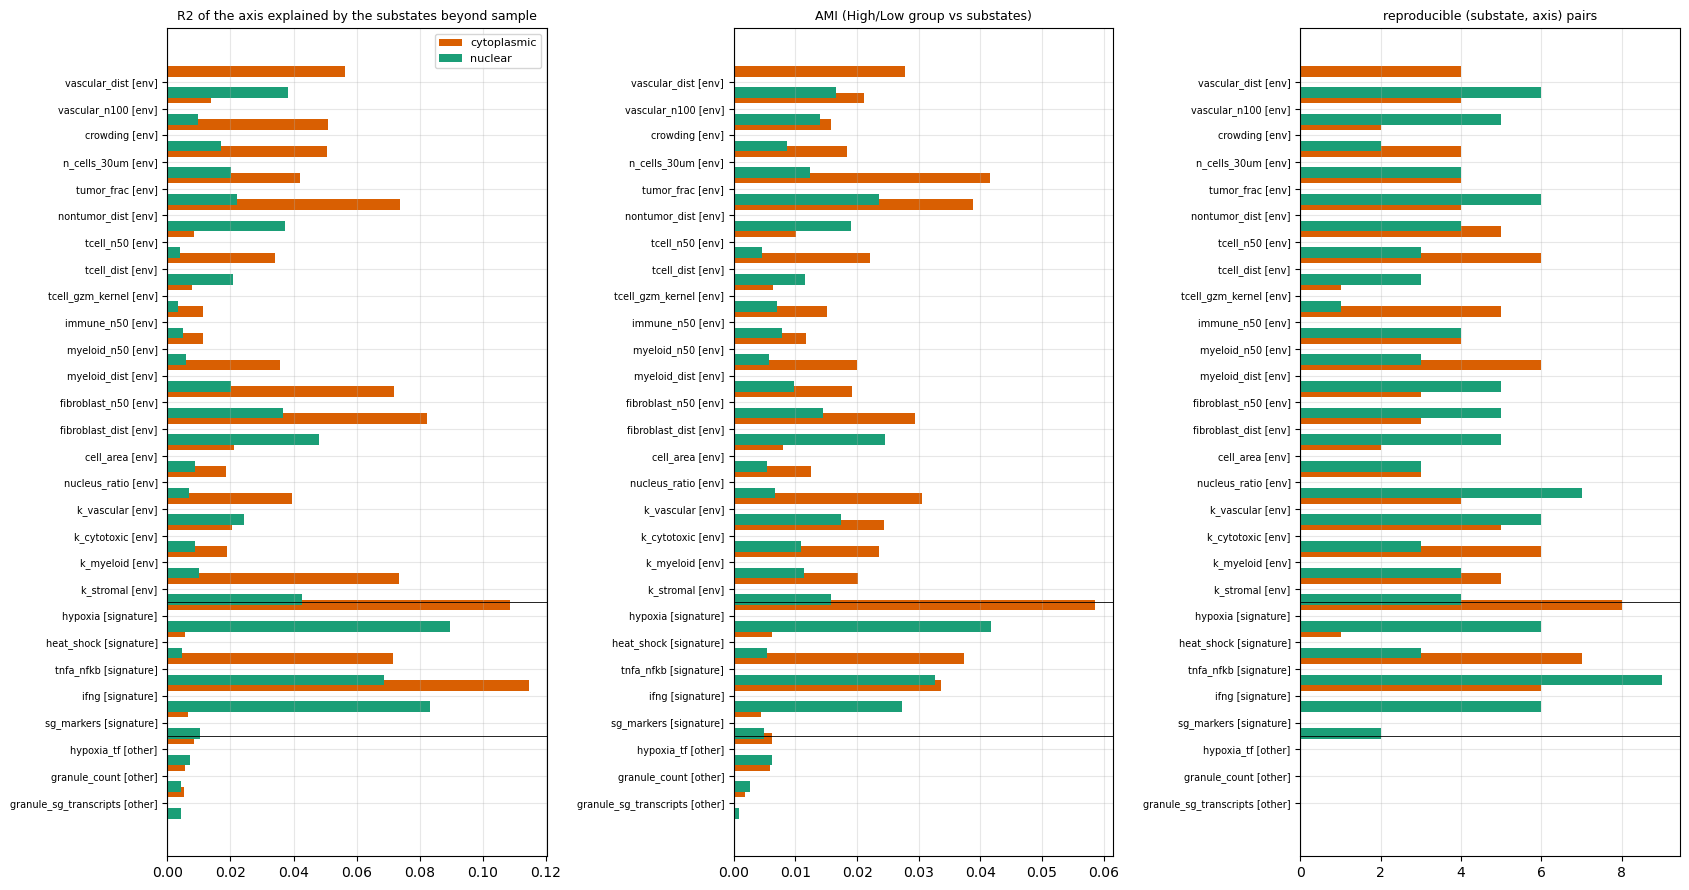

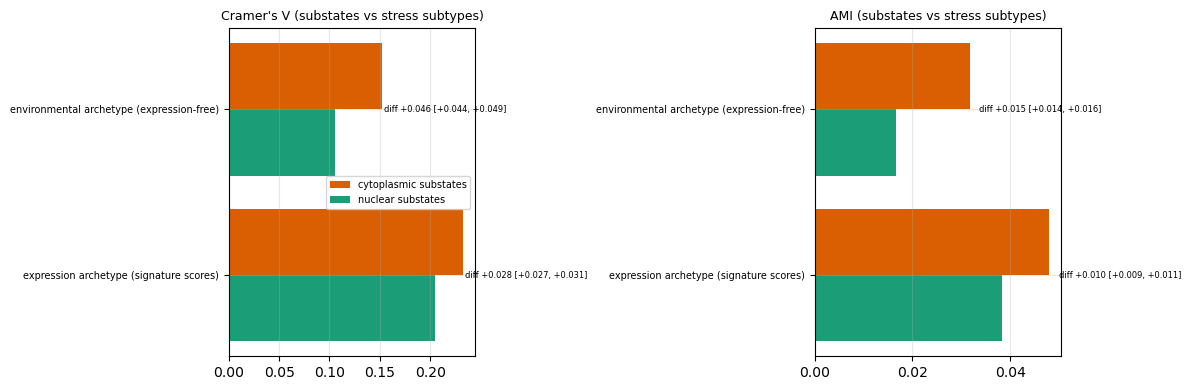

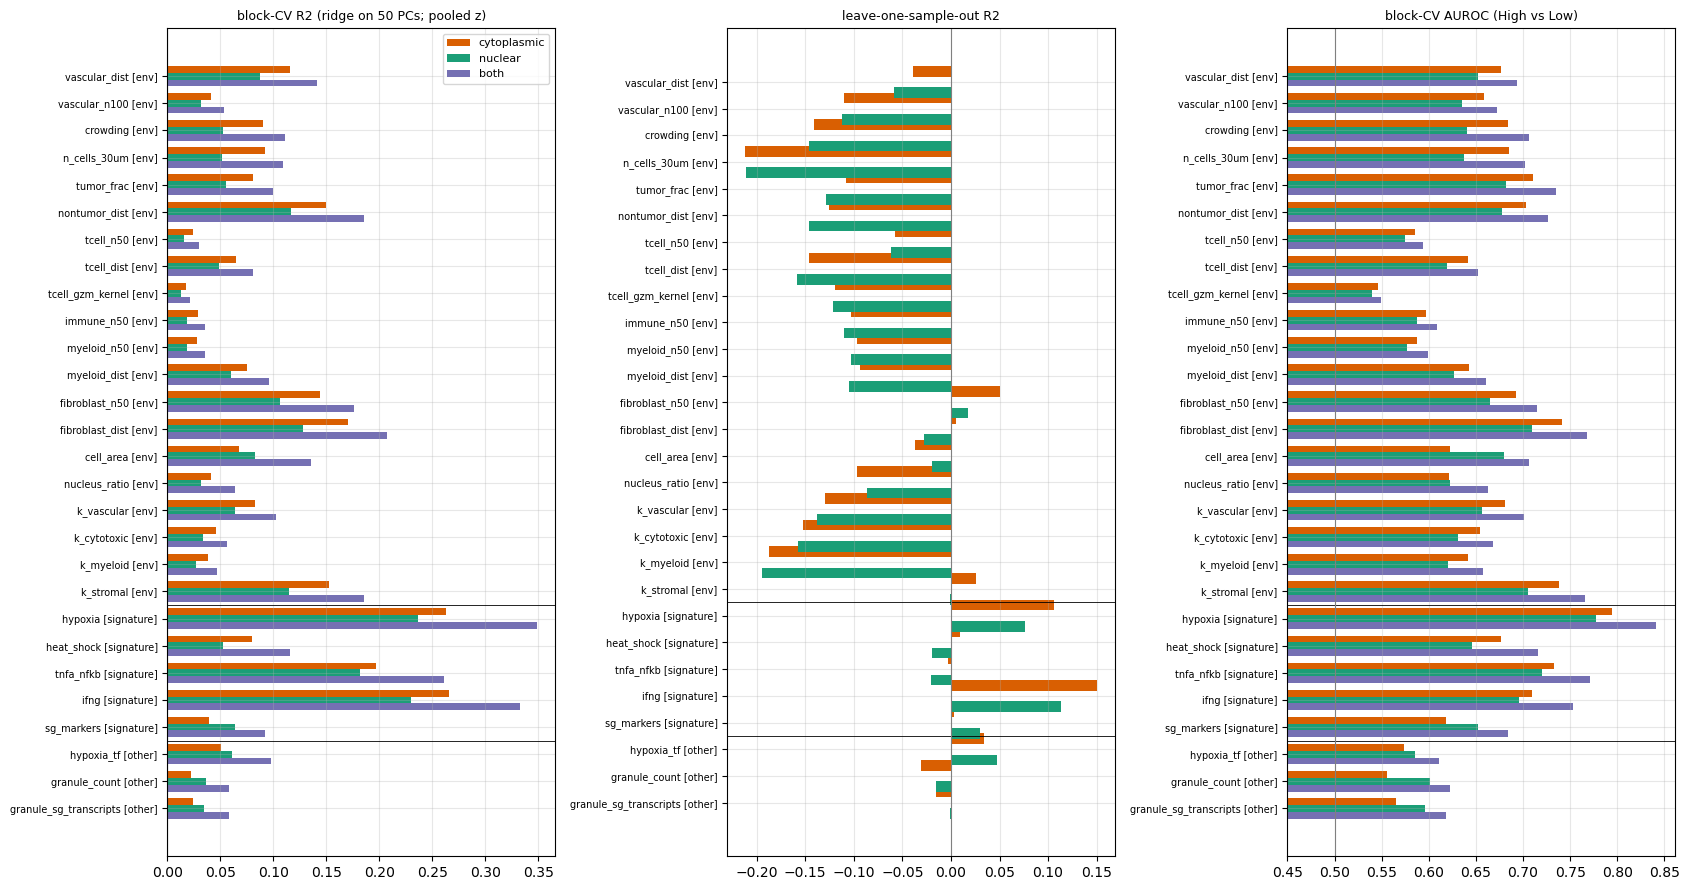

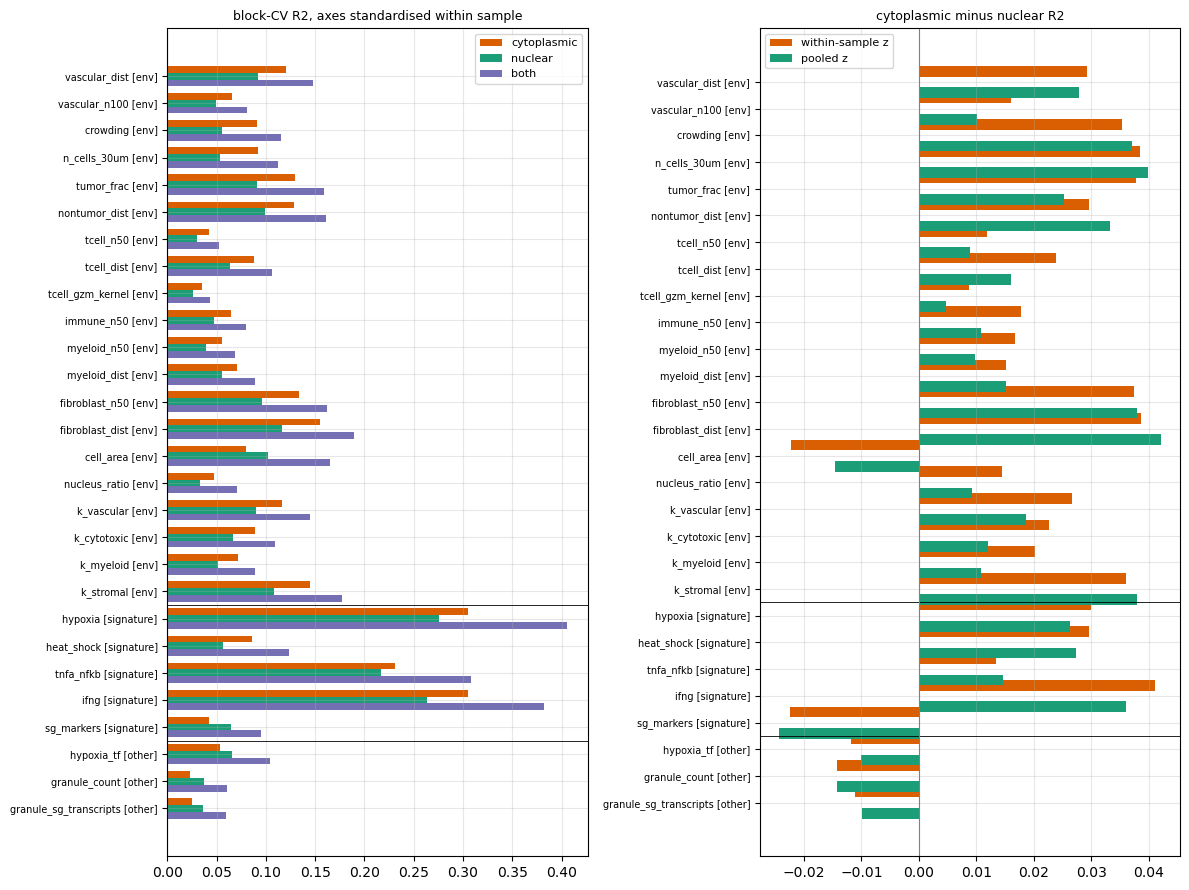

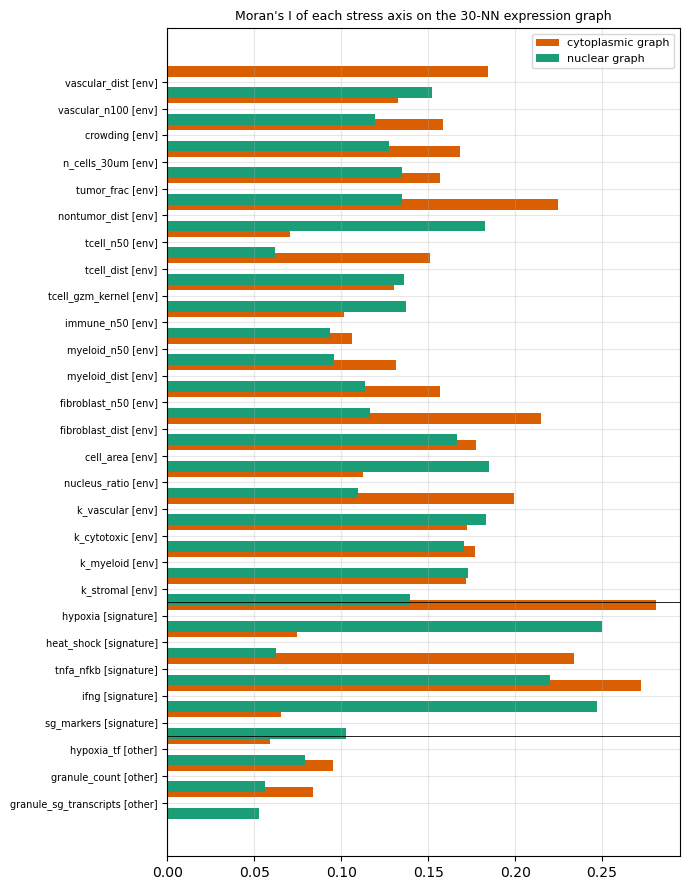

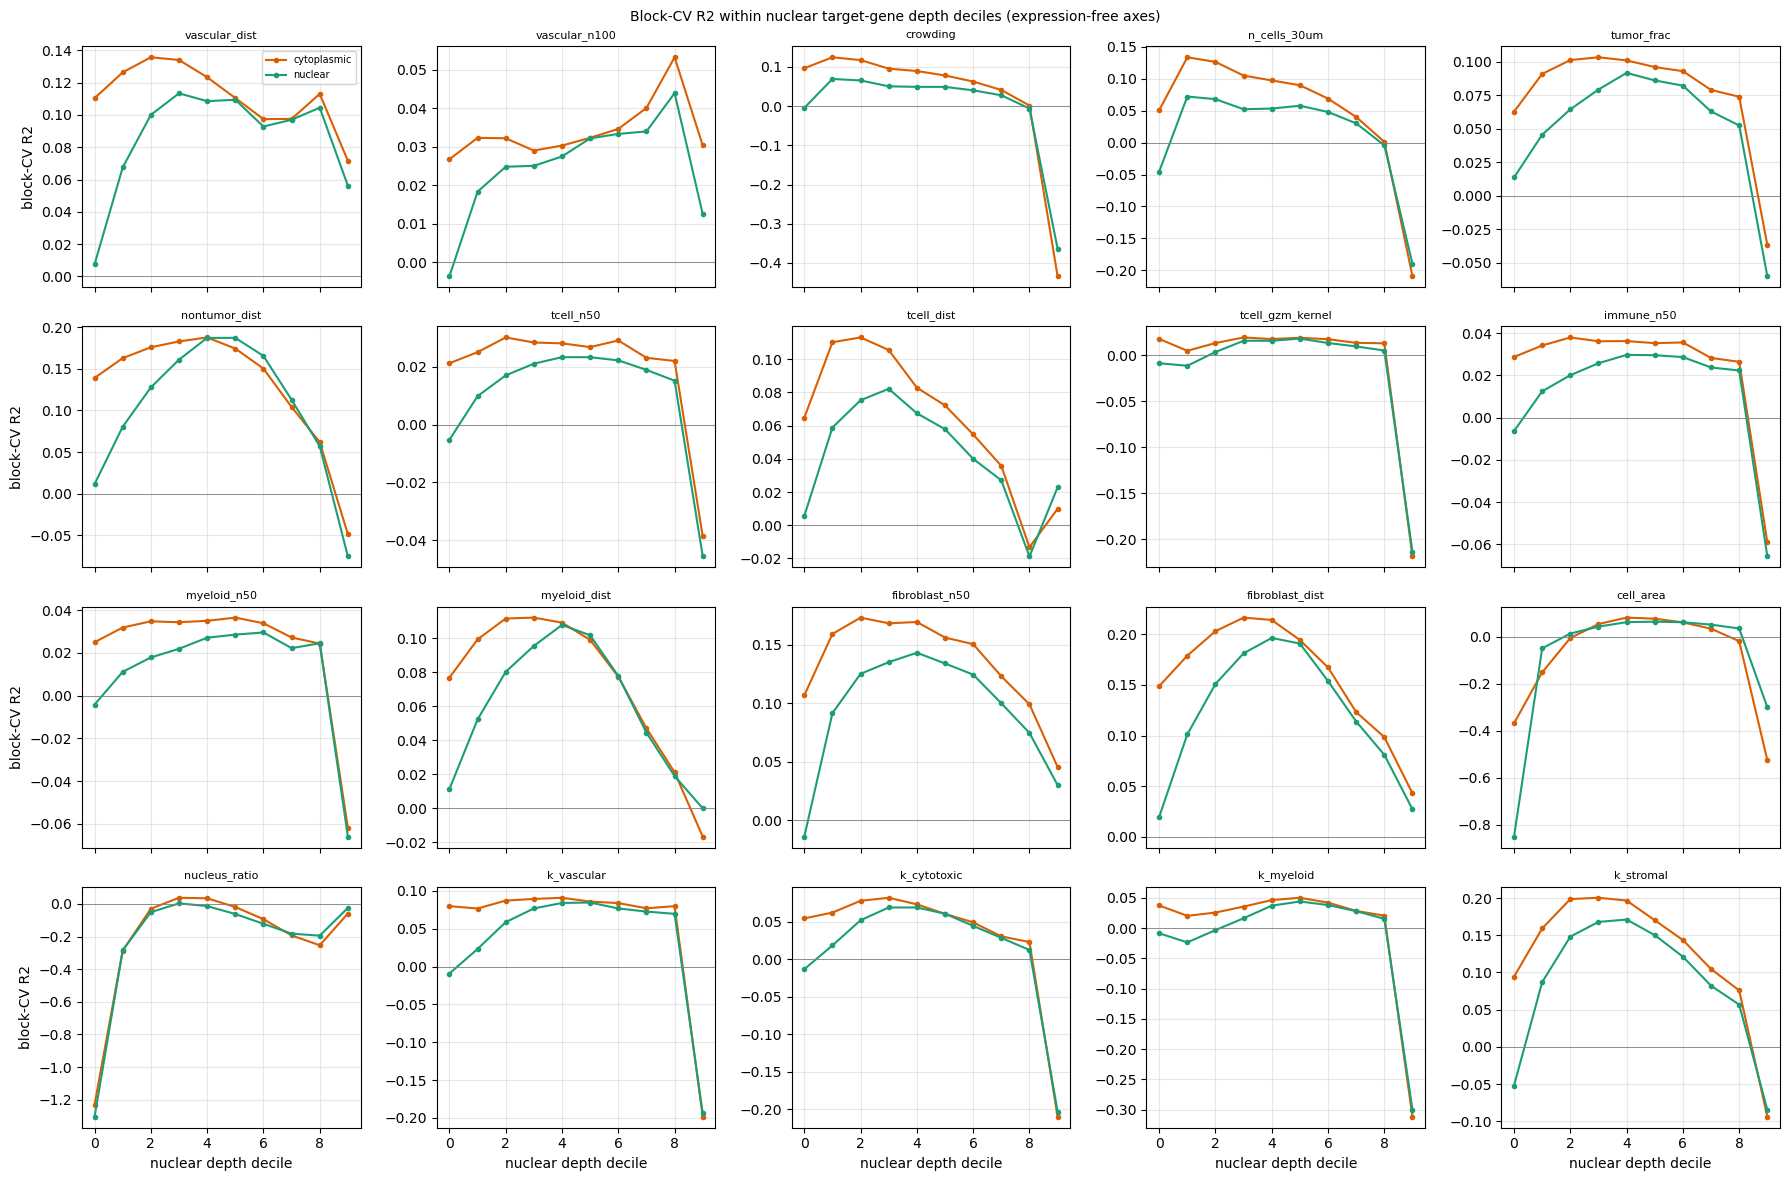

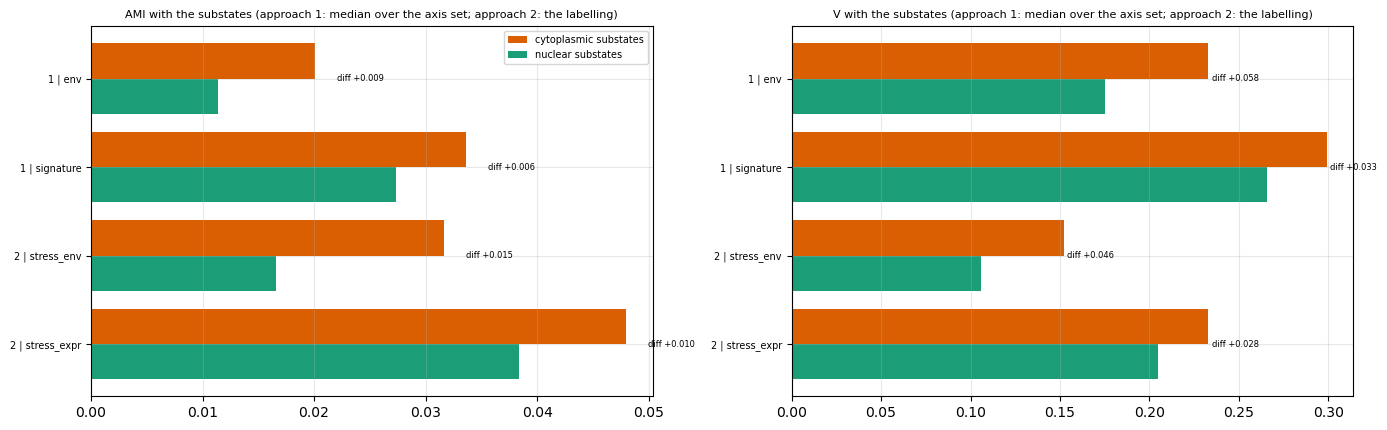

comparison figures written


In [11]:
# Comparison figures
names = [f"{a} [{AXIS_SET[a]}]" for a in AX_ORDER]
fig, axes = plt.subplots(1, 3, figsize=(17, 9))
sf.paired_bars(axes[0], cmp_axes["r2_cyto"], cmp_axes["r2_nuc"], names, "R2 of the axis explained by the substates beyond sample", row_breaks=ROW_BREAKS)
sf.paired_bars(axes[1], cmp_axes["AMI_cyto"], cmp_axes["AMI_nuc"], names, "AMI (High/Low group vs substates)", row_breaks=ROW_BREAKS)
sf.paired_bars(axes[2], cmp_axes["repro_pairs_cyto"], cmp_axes["repro_pairs_nuc"], names, "reproducible (substate, axis) pairs", row_breaks=ROW_BREAKS)
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(D["cmp"] + "correspondence_summary.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y = np.arange(len(ss))
for k, (m, t) in enumerate([("V", "Cramer's V (substates vs stress subtypes)"), ("AMI", "AMI (substates vs stress subtypes)")]):
    axes[k].barh(y - 0.2, ss[f"{m}_cyto"], 0.4, color=sf.COMP_COLORS["cyto"], label="cytoplasmic substates")
    axes[k].barh(y + 0.2, ss[f"{m}_nuc"], 0.4, color=sf.COMP_COLORS["nuc"], label="nuclear substates")
    axes[k].set_yticks(y); axes[k].set_yticklabels([STRESS_TITLES[s] for s in ss["stress_labelling"]], fontsize=7); axes[k].invert_yaxis(); axes[k].set_title(t, fontsize=9); axes[k].grid(alpha=0.3)
    for i, r in ss.iterrows():
        axes[k].text(max(r[f"{m}_cyto"], r[f"{m}_nuc"]) + 0.002, i, f"diff {r[f'{m}_diff']:+.3f} [{r[f'{m}_diff_ci_low']:+.3f}, {r[f'{m}_diff_ci_high']:+.3f}]", fontsize=6, va="center")
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(D["cmp"] + "stress_subtype_comparison.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(17, 9))
sf.paired_bars(axes[0], summary_c["r2_cv_cyto"], summary_c["r2_cv_nuc"], names, "block-CV R2 (ridge on 50 PCs; pooled z)", values_c=summary_c["r2_cv_joint"], row_breaks=ROW_BREAKS)
sf.paired_bars(axes[1], summary_c["r2_loso_cyto"], summary_c["r2_loso_nuc"], names, "leave-one-sample-out R2", row_breaks=ROW_BREAKS)
sf.paired_bars(axes[2], summary_c["auroc_cv_cyto"], summary_c["auroc_cv_nuc"], names, "block-CV AUROC (High vs Low)", values_c=summary_c["auroc_cv_joint"], xline=0.5, row_breaks=ROW_BREAKS)
axes[2].set_xlim(0.45, max(0.6, np.nanmax(summary_c[["auroc_cv_cyto", "auroc_cv_nuc", "auroc_cv_joint"]].values) + 0.02))
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(D["cmp"] + "information_cv.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 9))
sf.paired_bars(axes[0], summary_c["r2_ws_cyto"], summary_c["r2_ws_nuc"], names, "block-CV R2, axes standardised within sample", values_c=summary_c["r2_ws_joint"], row_breaks=ROW_BREAKS)
sf.paired_bars(axes[1], summary_c["r2_ws_cyto"] - summary_c["r2_ws_nuc"], summary_c["r2_cv_cyto"] - summary_c["r2_cv_nuc"], names, "cytoplasmic minus nuclear R2", label_a="within-sample z", label_b="pooled z", row_breaks=ROW_BREAKS)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8); fig.tight_layout(); fig.savefig(D["cmp"] + "information_within_sample.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 9))
sf.paired_bars(ax, summary_c["I_cyto"], summary_c["I_nuc"], names, "Moran's I of each stress axis on the 30-NN expression graph", label_a="cytoplasmic graph", label_b="nuclear graph", row_breaks=ROW_BREAKS)
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(D["cmp"] + "morans_i.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

fig, axes = plt.subplots(4, 5, figsize=(18, 12), sharex=True)
for k, a in enumerate(AX_ENV):
    ax_ = axes.flat[k]
    for comp in ["cyto", "nuc"]:
        d = info_depth[(info_depth["axis"] == a) & (info_depth["features"] == comp)]
        ax_.plot(d["nuc_depth_decile"], d["r2"], marker="o", ms=3, color=sf.COMP_COLORS[comp], label=COMP_NAME[comp])
    ax_.set_title(a, fontsize=8); ax_.grid(alpha=0.3); ax_.axhline(0, color="grey", lw=0.6)
    if k % 5 == 0: ax_.set_ylabel("block-CV R2")
    if k >= 15: ax_.set_xlabel("nuclear depth decile")
axes.flat[0].legend(fontsize=7); fig.suptitle("Block-CV R2 within nuclear target-gene depth deciles (expression-free axes)", fontsize=10)
fig.tight_layout(); fig.savefig(D["cmp"] + "information_by_depth.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

# signal-strength scoreboard
fig, axes = plt.subplots(1, 2, figsize=(14, 0.6 * len(sig_b) + 2))
y = np.arange(len(sig_b)); lab_rows = [f"{r['approach'][:1]} | {r['axis_set']}" for _, r in sig_b.iterrows()]
for k, m in enumerate(["AMI", "V"]):
    axes[k].barh(y - 0.2, sig_b[f"{m}_cyto"], 0.4, color=sf.COMP_COLORS["cyto"], label="cytoplasmic substates")
    axes[k].barh(y + 0.2, sig_b[f"{m}_nuc"], 0.4, color=sf.COMP_COLORS["nuc"], label="nuclear substates")
    axes[k].set_yticks(y); axes[k].set_yticklabels(lab_rows, fontsize=7); axes[k].invert_yaxis(); axes[k].grid(alpha=0.3)
    axes[k].set_title(f"{m} with the substates (approach 1: median over the axis set; approach 2: the labelling)", fontsize=8)
    for i, r in sig_b.iterrows():
        axes[k].text(max(r[f"{m}_cyto"], r[f"{m}_nuc"]) + 0.002, i, f"diff {r[f'{m}_diff']:+.3f}", fontsize=6, va="center")
axes[0].legend(fontsize=7); fig.tight_layout(); fig.savefig(D["cmp"] + "signal_strength.png", dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

# program-score difference heatmap
fig, ax = plt.subplots(figsize=(13, 7))
Dd = (R["cyto"]["Dpartial"] - R["nuc"]["Dpartial"])[:, [AX.index(a) for a in AX_ORDER]]
im = sf.heatmap(ax, Dd, R["cyto"]["prog_names"], names, "program score vs stress axis: partial Spearman, cytoplasmic minus nuclear", vmax=0.3)
for rbk in ROW_BREAKS: ax.axvline(rbk - 0.5, color="k", lw=0.8)
fig.colorbar(im, ax=ax, shrink=0.6, label="difference in rho"); fig.savefig(D["cmp"] + "program_axis_difference.png", dpi=200, bbox_inches="tight"); plt.close(fig)

# paired Sankey: cytoplasmic substates | stress labelling | nuclear substates (cells kept in both labellings)
both = R["cyto"]["keep"] & R["nuc"]["keep"]
for sl in STRESS_LABELLINGS:
    hl = set()
    for k, comp in [(0, "cyto"), (1, "nuc")]:
        lg = R[comp]["conts"][sl][1]; lg = lg[lg["reproducible"] & (lg["log2_enrichment"] > 0)]
        for _, r in lg.iterrows():
            hl.add((0, r["substate"], r["stress_subtype"]) if k == 0 else (1, r["stress_subtype"], r["substate"]))
    sf.alluvial_figure([("cytoplasmic substates", labels["cyto"]["label"].values.astype(object)[both]), (STRESS_TITLES[sl], STRESS[sl].values[both]), ("nuclear substates", labels["nuc"]["label"].values.astype(object)[both])],
                       D["cmp"] + f"sankey_pair_{sl}.png", f"cytoplasmic (left) and nuclear (right) substates around the {STRESS_TITLES[sl]}; ribbon width = cells, opaque = reproducibly enriched pair in that compartment", color_col=1, highlight=hl)

# paired spatial maps
for si, sname in enumerate(sample_levels):
    m = sample_codes == si
    cols = {"cytoplasmic substates": labels["cyto"]["label"].values.astype(object), "nuclear substates": labels["nuc"]["label"].values.astype(object),
            STRESS_TITLES["stress_env"]: STRESS["stress_env"].values, STRESS_TITLES["stress_expr"]: STRESS["stress_expr"].values}
    sf.spatial_labels_figure(stress, cols, m, f"{sname}: cytoplasmic vs nuclear substates next to the stress subtypes", D["cmp"] + f"spatial_pair_{sname}.png")
print("comparison figures written")

## 5. Summaries

In [12]:
def fmt_row(r):
    return f"R2 cv {r['r2_cv_cyto']:.3f}/{r['r2_cv_nuc']:.3f}/{r['r2_cv_joint']:.3f}  within-sample {r['r2_ws_cyto']:.3f}/{r['r2_ws_nuc']:.3f}  loso {r['r2_loso_cyto']:.3f}/{r['r2_loso_nuc']:.3f}  auroc {r['auroc_cv_cyto']:.3f}/{r['auroc_cv_nuc']:.3f}  I {r['I_cyto']:.3f}/{r['I_nuc']:.3f}"

L = [f"Cytoplasmic vs nuclear target-gene substates and tumor stress (question b); pooled cells n = {len(stress):,}", ""]
L.append("Approach 1 (stress groups across substates; AB_comparison.csv): cytoplasmic vs nuclear substates")
for vname, axset in AXSETS + [("other", AX_OTHER)]:
    c = cmp_axes.loc[axset]
    L.append(f"  {vname:<9s} ({len(axset)} axes): median AMI {c['AMI_cyto'].median():.3f} vs {c['AMI_nuc'].median():.3f} (cyto higher on {(c['AMI_cyto'] > c['AMI_nuc']).sum()}); median V {c['V_cyto'].median():.3f} vs {c['V_nuc'].median():.3f}; "
             f"median R2 beyond sample {c['r2_cyto'].median():.3f} vs {c['r2_nuc'].median():.3f} (cyto higher on {(c['r2_cyto'] > c['r2_nuc']).sum()}; R2 difference CI excludes 0 for {int(((c['r2_diff_ci_low'] > 0) | (c['r2_diff_ci_high'] < 0)).sum())} axes)")
L.append("")
L.append("Approach 2 (explicit stress subtypes; stress_subtype_comparison.csv)")
for _, r in ss.iterrows():
    L.append(f"  {r['stress_labelling']:<24s} AMI {r['AMI_cyto']:.3f} vs {r['AMI_nuc']:.3f} (diff {r['AMI_diff']:+.3f} [{r['AMI_diff_ci_low']:+.3f}, {r['AMI_diff_ci_high']:+.3f}]); V {r['V_cyto']:.3f} vs {r['V_nuc']:.3f} (diff {r['V_diff']:+.3f} [{r['V_diff_ci_low']:+.3f}, {r['V_diff_ci_high']:+.3f}]); "
             f"cluster-level AMI {r['AMI_cluster_cyto']:.3f} vs {r['AMI_cluster_nuc']:.3f}")
L.append("")
L.append("Analysis C (information in the matched PCs; C_summary.csv): block-CV R2 cyto/nuc/joint, within-sample standardised R2 cyto/nuc, LOSO R2, AUROC, Moran's I")
for vname, axset in AXSETS + [("other", AX_OTHER)]:
    sub = summary_c.loc[axset]
    L.append(f"  {vname} axes (n = {len(axset)}): cyto better in block-CV R2 for {(sub['r2_cv_cyto'] > sub['r2_cv_nuc']).sum()}, within-sample R2 for {(sub['r2_ws_cyto'] > sub['r2_ws_nuc']).sum()}, LOSO for {(sub['r2_loso_cyto'] > sub['r2_loso_nuc']).sum()}, AUROC for {(sub['auroc_cv_cyto'] > sub['auroc_cv_nuc']).sum()}, Moran's I for {(sub['I_cyto'] > sub['I_nuc']).sum()}; "
             f"median R2 cv {sub['r2_cv_cyto'].median():.3f} vs {sub['r2_cv_nuc'].median():.3f} (joint {sub['r2_cv_joint'].median():.3f}); median within-sample R2 {sub['r2_ws_cyto'].median():.3f} vs {sub['r2_ws_nuc'].median():.3f}")
    for a in axset:
        L.append(f"     {a:<22s} {fmt_row(summary_c.loc[a])}  cyto better in {int(summary_c.loc[a, 'n_samples_cyto_better_r2_ws'])}/5 samples (within-sample R2)")
L.append("")
L.append("Depth strata (block-CV R2 within nuclear depth deciles, env axes): cyto minus nuc, decile 1 (shallow) .. 10 (deep)")
for a in AX_ENV:
    d = info_depth[info_depth["axis"] == a].pivot(index="nuc_depth_decile", columns="features", values="r2")
    L.append(f"     {a:<22s} " + " ".join(f"{v:+.2f}" for v in (d["cyto"] - d["nuc"]).values))
L.append("")
L.append("Signal-strength scoreboard (signal_strength.csv): cytoplasmic minus nuclear")
for _, r in sig_b.iterrows():
    extra = f"; median R2 beyond sample diff {r['R2_diff']:+.3f} [{r['R2_diff_ci_low']:+.3f}, {r['R2_diff_ci_high']:+.3f}]; PC block-CV R2 {r['PC_r2_cv_cyto']:.3f} vs {r['PC_r2_cv_nuc']:.3f} (within-sample {r['PC_r2_ws_cyto']:.3f} vs {r['PC_r2_ws_nuc']:.3f})" if r["approach"].startswith("1") else f" [{r['AMI_diff_ci_low']:+.3f}, {r['AMI_diff_ci_high']:+.3f}]"
    L.append(f"  {r['approach'][:1]} | {r['axis_set']:<12s} AMI {r['AMI_cyto']:.3f} vs {r['AMI_nuc']:.3f} (diff {r['AMI_diff']:+.3f}, ratio {r['AMI_ratio']:.2f}); V {r['V_cyto']:.3f} vs {r['V_nuc']:.3f} (diff {r['V_diff']:+.3f}){extra}")
best_b = sig_b.sort_values("AMI_diff", ascending=False).iloc[0]
L.append(f"  strongest cytoplasmic-vs-nuclear difference (AMI): approach {best_b['approach']} / {best_b['axis_set']} (diff {best_b['AMI_diff']:+.3f}, ratio {best_b['AMI_ratio']:.2f})")
cmp_summary = "\n".join(L)
open(D["cmp"] + "summary.txt", "w").write(cmp_summary + "\n")
print(cmp_summary)

Cytoplasmic vs nuclear target-gene substates and tumor stress (question b); pooled cells n = 623,838

Approach 1 (stress groups across substates; AB_comparison.csv): cytoplasmic vs nuclear substates
  env       (20 axes): median AMI 0.020 vs 0.011 (cyto higher on 19); median V 0.233 vs 0.175; median R2 beyond sample 0.035 vs 0.019 (cyto higher on 20; R2 difference CI excludes 0 for 20 axes)
  signature (5 axes): median AMI 0.034 vs 0.027 (cyto higher on 4); median V 0.299 vs 0.266; median R2 beyond sample 0.072 vs 0.069 (cyto higher on 4; R2 difference CI excludes 0 for 5 axes)
  other     (3 axes): median AMI 0.006 vs 0.003 (cyto higher on 3); median V 0.129 vs 0.084; median R2 beyond sample 0.006 vs 0.004 (cyto higher on 3; R2 difference CI excludes 0 for 3 axes)

Approach 2 (explicit stress subtypes; stress_subtype_comparison.csv)
  stress_env               AMI 0.032 vs 0.017 (diff +0.015 [+0.014, +0.016]); V 0.152 vs 0.106 (diff +0.046 [+0.044, +0.049]); cluster-level AMI 0.037 vs 

In [13]:
# Root summary: the answers and the approach to proceed with
sa = R["cyto"]["signal"]; sb = sig_b
best_a = sa.sort_values("max_AMI", ascending=False).iloc[0]
best_a1 = sa[sa["approach"].str.startswith("1")].sort_values("max_AMI", ascending=False).iloc[0]
best_a2 = sa[sa["approach"].str.startswith("2")].sort_values("max_AMI", ascending=False).iloc[0]
best_b = sb.sort_values("AMI_diff", ascending=False).iloc[0]
best_b1 = sb[sb["approach"].str.startswith("1")].sort_values("AMI_diff", ascending=False).iloc[0]
best_b2 = sb[sb["approach"].str.startswith("2")].sort_values("AMI_diff", ascending=False).iloc[0]
L = ["Tumor stress vs target-gene substates: overall summary (6_stress_substates.ipynb)", f"pooled tumor cells of BC/OC/CC/LC/Prostate, n = {len(stress):,}; 28 stress axes (20 expression-free, 5 canonical signatures, 3 other); 2 stress labellings (environmental archetype, expression archetype)", ""]
L.append("(a) Are the cytoplasmic target-gene substates connected to tumor stress?  -> see cytoplasmic/summary.txt")
L.append(f"    approach 1 (stress groups across substates): best axis set {best_a1['axis_set']}: max AMI {best_a1['max_AMI']:.3f}, max V {best_a1['max_V']:.3f}, max R2 beyond sample {best_a1['max_R2_beyond_sample']:.3f}, {best_a1['n_reproducible']} reproducible pairs; strongest {best_a1['strongest']}")
L.append(f"    approach 2 (explicit stress subtypes): best labelling {best_a2['axis_set']}: AMI {best_a2['max_AMI']:.3f}, V {best_a2['max_V']:.3f}, {best_a2['n_reproducible']} reproducible cells; strongest {best_a2['strongest']}")
L.append(f"    => strongest signal for (a): approach {best_a['approach']} / {best_a['axis_set']}")
L.append("")
L.append("(b) Is cytoplasmic expression of the target genes more closely related to stress than nuclear expression?  -> see comparison/summary.txt")
L.append(f"    approach 1 best: {best_b1['axis_set']} axes: median AMI {best_b1['AMI_cyto']:.3f} vs {best_b1['AMI_nuc']:.3f} (ratio {best_b1['AMI_ratio']:.2f}); median R2 beyond sample {best_b1['R2_cyto']:.3f} vs {best_b1['R2_nuc']:.3f} (diff {best_b1['R2_diff']:+.3f} [{best_b1['R2_diff_ci_low']:+.3f}, {best_b1['R2_diff_ci_high']:+.3f}]); PC block-CV R2 {best_b1['PC_r2_cv_cyto']:.3f} vs {best_b1['PC_r2_cv_nuc']:.3f}, within-sample {best_b1['PC_r2_ws_cyto']:.3f} vs {best_b1['PC_r2_ws_nuc']:.3f}")
L.append(f"    approach 2 best: {best_b2['axis_set']}: AMI {best_b2['AMI_cyto']:.3f} vs {best_b2['AMI_nuc']:.3f} (diff {best_b2['AMI_diff']:+.3f} [{best_b2['AMI_diff_ci_low']:+.3f}, {best_b2['AMI_diff_ci_high']:+.3f}], ratio {best_b2['AMI_ratio']:.2f})")
env_c = summary_c.loc[AX_ENV]
L.append(f"    expression-free axes, PCs: cyto better in block-CV R2 for {(env_c['r2_cv_cyto'] > env_c['r2_cv_nuc']).sum()}/20 (median {env_c['r2_cv_cyto'].median():.3f} vs {env_c['r2_cv_nuc'].median():.3f}, joint {env_c['r2_cv_joint'].median():.3f}); within-sample standardised for {(env_c['r2_ws_cyto'] > env_c['r2_ws_nuc']).sum()}/20 (median {env_c['r2_ws_cyto'].median():.3f} vs {env_c['r2_ws_nuc'].median():.3f}); Moran's I for {(env_c['I_cyto'] > env_c['I_nuc']).sum()}/20")
L.append(f"    => strongest cytoplasmic-vs-nuclear difference for (b): approach {best_b['approach']} / {best_b['axis_set']} (AMI diff {best_b['AMI_diff']:+.3f}, ratio {best_b['AMI_ratio']:.2f})")
L.append("")
L.append("Folders: stress_axes/ (stress table, composites, stress subtypes, maps), cytoplasmic/ and nuclear/ (question a per labelling), comparison/ (question b)")
L.append("Signatures use their canonical gene lists; the minus-634 arm was retired on 2026-11-08 (weaker on every metric in the review run, same associations); rationale in plans/stress_substate_exploration.md")
root = "\n".join(L)
open(OUT + "summary.txt", "w").write(root + "\n")
print(root)

Tumor stress vs target-gene substates: overall summary (6_stress_substates.ipynb)
pooled tumor cells of BC/OC/CC/LC/Prostate, n = 623,838; 28 stress axes (20 expression-free, 5 canonical signatures, 3 other); 2 stress labellings (environmental archetype, expression archetype)

(a) Are the cytoplasmic target-gene substates connected to tumor stress?  -> see cytoplasmic/summary.txt
    approach 1 (stress groups across substates): best axis set signature: max AMI 0.059, max V 0.398, max R2 beyond sample 0.115, 22 reproducible pairs; strongest Interferon x ifng (log2 OR +3.30)
    approach 2 (explicit stress subtypes): best labelling stress_expr: AMI 0.048, V 0.233, 20 reproducible cells; strongest Interferon x Interferon (IFNG) (log2 enr +1.85)
    => strongest signal for (a): approach 1: stress groups across substates / signature

(b) Is cytoplasmic expression of the target genes more closely related to stress than nuclear expression?  -> see comparison/summary.txt
    approach 1 best: e